# Prioritizing Safety Validation for Zoox's Robotaxi Expansion: Which Crash Scenarios Need Attention First?

**Business problem:** Zoox is expanding driverless robotaxi service into new cities. Its safety and validation teams have limited testing capacity, so they need to know which real-world crash scenarios to prioritize in simulation and on-road validation work.

**Key questions:**
1. Which crash scenarios are over-represented in Zoox's crashes compared to peers like Waymo?
2. Do patterns seen in the test fleet carry over to the driverless robotaxi?
3. Do scenarios differ by city (San Francisco vs. Las Vegas), which matters for planning new-city launches?

**Approach & data:** This analysis uses NHTSA's public Standing General Order (SGO) crash-reporting data to benchmark Zoox's crash *characteristics* against Waymo (the only other large-scale commercial robotaxi operator) and smaller ADS peers (Cruise, Avride, and others).

**Data source & credit:** [NHTSA Standing General Order (SGO) Crash Reporting](https://www.nhtsa.gov/laws-regulations/standing-general-order-crash-reporting) — all crash data is public and comes from the National Highway Traffic Safety Administration's Office of Defects Investigation. This notebook only cleans and analyzes what NHTSA has already collected and published; see the [README](../README.md) for the full data-source note.

**Framing constraint, up front:** this dataset is a self-reported *incident log*, not a normalized safety record, and it is **not adjusted for miles driven**. So this can never answer "is Zoox safer than Waymo" or rank companies by safety — it can only answer "given that a crash happened, does it look different from peers, and is that difference large and consistent enough to prioritize for validation work." Every analysis here is built around that narrower, answerable question.


## Executive Summary

- **Scenario ranking (which scenarios are over-represented?):** two scenarios are both large and statistically significant against Waymo, even after correcting for running 13 tests: right turns into a passenger car (6.3% of Zoox's crashes vs. 0.65% of Waymo's - a 9.7x ratio) and being rear-ended by a passenger car while stopped (13.3% vs. 6.1% - a 2.2x ratio). These are the two concrete scenarios we'd prioritize for validation, not a vague "Zoox crashes differently."
- **Robotaxi carryover (does the pattern transfer?):** the rear-end scenario carries over to the robotaxi (10.4% vs. Waymo's 6.1%); the right-turn scenario has too few robotaxi crashes yet (1) to say either way. Separately, and importantly: the much-discussed "Zoox has a higher injury rate than Waymo" finding (20.9% vs. 8.8% in aggregate) does **not** carry over to the robotaxi - it's a **Highlander test-fleet effect** (25.5%, still significant after correction); the robotaxi's own injury rate (10.4%, n=48) is statistically indistinguishable from Waymo's.
- **City differences (does it vary by city?):** in this still-small sample, Las Vegas shows nearly double San Francisco's right-turn crash share (17.7% vs. 9.5%, n=62 and 84), suggesting road-network design - not just the vehicle - shapes the scenario mix. That matters for predicting a new city's profile before it has any crash history of its own.
- Zoox's reported crashes split 110 Highlander test fleet (Zoox software, safety operator onboard) / 48 Zoox robotaxi (driverless, no operator), and the robotaxi has outnumbered the Highlander fleet in monthly crash volume since May 2024, though the test fleet remains active in parallel.
- None of this is a safety ranking - the dataset has no mileage or exposure data - but it points to two specific, statistically-grounded scenarios worth prioritizing in simulation and on-road validation ahead of new-city launches, rather than a generic "investigate everything."


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_colwidth", 80)

# swap this to an S3 path later, nothing else needs to change
DATA_DIR = Path("../data/raw")

# Zoox gets its own color so it's traceable across every chart
ZOOX_COLOR = "#8E44AD"
PEER_COLOR = "#B0B0B0"

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110


## 1. Load & Inspect


In [2]:
# low_memory=False avoids dtype-guessing warnings on these wide, mixed-type files
current = pd.read_csv(DATA_DIR / "ads_current.csv", low_memory=False)
archive = pd.read_csv(DATA_DIR / "ads_archive.csv", low_memory=False)

print(f"ads_current.csv : {current.shape[0]:,} rows x {current.shape[1]} columns")
print(f"ads_archive.csv : {archive.shape[0]:,} rows x {archive.shape[1]} columns")


ads_current.csv : 1,478 rows x 116 columns
ads_archive.csv : 2,295 rows x 137 columns


### Column differences between the two files

Before combining anything, let's see exactly which columns exist in both files (common schema we can safely stack), and which exist in only one (fields we'll either drop, keep as file-specific, or need to carefully re-map).


In [3]:
current_cols = set(current.columns)
archive_cols = set(archive.columns)

common_cols = current_cols & archive_cols
only_in_current = current_cols - archive_cols
only_in_archive = archive_cols - current_cols

print(f"Common columns:        {len(common_cols)}")
print(f"Only in ads_current:   {len(only_in_current)}")
print(f"Only in ads_archive:   {len(only_in_archive)}")


Common columns:        89
Only in ads_current:   27
Only in ads_archive:   48


In [4]:
print("=== Columns ONLY in ads_current.csv (3rd Amendment fields, Jun 2025+) ===")
for c in sorted(only_in_current):
    print(" -", c)


=== Columns ONLY in ads_current.csv (3rd Amendment fields, Jun 2025+) ===
 - Any Air Bags Deployed?
 - Automation Feature Version
 - Automation Feature Version CBI
 - Engagement Status
 - Make - Unknown
 - Roadway-Degraded Surface
 - Roadway-Missing/Degraded Marking
 - Roadway-No Unusual Conditions
 - Roadway-Other-See Narrative
 - Roadway-Traffic Incident
 - Roadway-Unknown
 - Roadway-Wet Surface Condition
 - Roadway-Work Zone
 - Source - Internal Process Review
 - Source - NHTSA VOQ
 - Source - Other - See Narrative
 - Source - Other Entity
 - Source - State or Other Agency
 - VIN Decoded
 - Was Any Vehicle Towed?
 - Weather - Dust Storm
 - Weather - Fog/Smoke/Haze
 - Weather - Partly Cloudy
 - Weather - Severe Hurricane
 - Weather - Structure-Indoor
 - Weather - Unk - See Narrative
 - Were All Passengers Belted?


In [5]:
print("=== Columns ONLY in ads_archive.csv (older/legacy fields, 2021-2025) ===")
for c in sorted(only_in_archive):
    print(" -", c)


=== Columns ONLY in ads_archive.csv (older/legacy fields, 2021-2025) ===
 - ADAS/ADS Hardware Version
 - ADAS/ADS Hardware Version - Unk
 - ADAS/ADS Hardware Version CBI
 - ADAS/ADS Software Version
 - ADAS/ADS Software Version - Unk
 - ADAS/ADS Software Version CBI
 - ADAS/ADS System Version
 - ADAS/ADS System Version - Unk
 - ADAS/ADS System Version CBI
 - ADS Equipped?
 - CP Any Air Bags Deployed?
 - CP Was Vehicle Towed?
 - Federal Reg. Exemption - No
 - Federal Reg. Exemption - Unk
 - Federal Regulatory Exemption?
 - Inv. Officer Email - Unknown
 - Inv. Officer Name - Unknown
 - Inv. Officer Phone - Unknown
 - Investigating Officer Email
 - Investigating Officer Name
 - Investigating Officer Phone
 - Law Enforcement Investigating?
 - Lighting
 - Mileage
 - Mileage - Unknown
 - Notice Received Date
 - Other Federal Reg. Exemption
 - Other Reporting Entities?
 - Other Reporting Entities? - NA
 - Other Reporting Entities? - Unk
 - Posted Speed Limit (MPH)
 - Posted Speed Limit - Unkn

### Dtypes, null rates, and key-column uniques

Quick profile of both files before we decide what to drop and how to combine.


In [6]:
def null_profile(df, name):
    prof = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "null_pct": (df.isna().mean() * 100).round(1),
        "n_unique": df.nunique(dropna=True),
    }).sort_values("null_pct", ascending=False)
    print(f"--- {name}: columns with >50% nulls ({(prof['null_pct'] > 50).sum()} of {len(prof)}) ---")
    return prof

current_profile = null_profile(current, "ads_current")
archive_profile = null_profile(archive, "ads_archive")
current_profile.head(15)


--- ads_current: columns with >50% nulls (4 of 116) ---
--- ads_archive: columns with >50% nulls (10 of 137) ---


,dtype,null_pct,n_unique
Driver / Operator Type,str,84.1,4
Investigating Agency,str,76.1,93
Report Year,float64,53.2,2
Report Month,float64,53.2,12
Serial Number,str,21.2,1
Zip Code,str,13.7,1
Address,str,13.7,1
CP Contact Area - Right,str,8.0,2
CP Contact Area - Front Right,str,8.0,2
CP Contact Area - Unknown,str,8.0,2


In [7]:
# sanity check the columns we'll lean on most before cleaning
for col in ["Reporting Entity", "State", "Crash With", "Highest Injury Severity Alleged"]:
    print(f"\n=== {col} ===")
    print(pd.concat([current[col], archive[col]]).value_counts(dropna=False).head(10))



=== Reporting Entity ===
Reporting Entity
Waymo LLC                        2500
Cruise LLC                        207
General Motors, LLC               201
Zoox, Inc.                        189
Transdev Alternative Services     188
Avride Inc.                        93
May Mobility                       48
Tesla, Inc.                        46
Motional                           30
Ford Motor Company                 26
Name: count, dtype: int64

=== State ===
State
CA     1457
CA      773
AZ      421
TX      323
TX      219
AZ      196
GA       76
NV       72
NV       42
FL       42
Name: count, dtype: int64

=== Crash With ===
Crash With
Passenger Car            1355
SUV                       805
Pickup Truck              352
Other, see Narrative      327
Heavy Truck               279
Other Fixed Object        140
Van                       125
Non-Motorist: Cyclist     110
Bus                        83
Motorcycle                 66
Name: count, dtype: int64

=== Highest Injury Severit

## 2. Data Cleaning

- Dedupe on `Report ID`, keep latest `Report Version`
- Map the handful of fields renamed between schemas, then combine on the common columns (tagging `data_source`)
- Strip whitespace, parse dates (month-granularity only)
- **Dedupe cross-company duplicates**: the same physical crash is sometimes filed by two entities (operator + manufacturer) under the same `Same Incident ID` but different `Report ID` - keep one row per incident
- Replace the CBI redaction marker with an explicit `"Redacted"` category
- Drop columns that are >75% null, logged below


In [8]:
# same crash gets re-filed as facts get confirmed - keep only the latest version
def dedupe_latest_version(df):
    return (
        df.sort_values("Report Version")
          .drop_duplicates(subset="Report ID", keep="last")
          .reset_index(drop=True)
    )

current_dd = dedupe_latest_version(current)
archive_dd = dedupe_latest_version(archive)

print(f"ads_current: {len(current):,} rows -> {len(current_dd):,} unique crashes after dedup")
print(f"ads_archive: {len(archive):,} rows -> {len(archive_dd):,} unique crashes after dedup")


ads_current: 1,478 rows -> 1,437 unique crashes after dedup
ads_archive: 2,295 rows -> 1,899 unique crashes after dedup


In [9]:
# a handful of fields are the same concept renamed across schemas - map them
# before taking the column intersection, or we'd lose them as "file-specific"
ARCHIVE_RENAME = {
    "SV Was Vehicle Towed?": "Was Any Vehicle Towed?",
    "SV Any Air Bags Deployed?": "Any Air Bags Deployed?",
    "SV Were All Passengers Belted?": "Were All Passengers Belted?",
}
archive_dd = archive_dd.rename(columns=ARCHIVE_RENAME)

current_cols = set(current_dd.columns)
archive_cols = set(archive_dd.columns)
common_cols = sorted(current_cols & archive_cols)

print(f"Common columns after explicit re-mapping: {len(common_cols)}")

# tag provenance so any row can be traced back to its source schema
current_common = current_dd[common_cols].copy()
current_common["data_source"] = "current"
archive_common = archive_dd[common_cols].copy()
archive_common["data_source"] = "archive"

crashes = pd.concat([archive_common, current_common], ignore_index=True)
print(f"Combined crashes: {len(crashes):,} rows x {crashes.shape[1]} columns")


Common columns after explicit re-mapping: 92
Combined crashes: 3,336 rows x 93 columns


In [10]:
# strip whitespace everywhere - raw data has "CA" and "CA " as separate states
str_cols = crashes.select_dtypes(include=["object", "string"]).columns
for c in str_cols:
    crashes[c] = crashes[c].str.strip()

# dates are only reported at month granularity (e.g. "JUL-2026"), no day
crashes["Report Submission Date"] = pd.to_datetime(crashes["Report Submission Date"], format="%b-%Y", errors="coerce")
crashes["Incident Date"] = pd.to_datetime(crashes["Incident Date"], format="%b-%Y", errors="coerce")
crashes["incident_month"] = crashes["Incident Date"].dt.to_period("M").dt.to_timestamp()

for c in ["Report Submission Date", "Incident Date", "incident_month"]:
    print(f"{c}: min={crashes[c].min()}, max={crashes[c].max()}, nulls={crashes[c].isna().sum()}")


Report Submission Date: min=2021-07-01 00:00:00, max=2026-08-01 00:00:00, nulls=0
Incident Date: min=2021-07-01 00:00:00, max=2026-08-01 00:00:00, nulls=1
incident_month: min=2021-07-01 00:00:00, max=2026-08-01 00:00:00, nulls=1


In [11]:
# Report ID dedup only removes repeat filings by the SAME company. The same
# physical crash can also be filed independently by two different entities
# (operator + manufacturer) sharing a "Same Incident ID" but different Report
# IDs - e.g. Cruise (operator) and General Motors (manufacturer) both report
# the same Cruise AV crash. Keep one row per incident, preferring the operator.
import re

def normalize_entity(name):
    """Strip punctuation/corporate suffixes so entity names compare cleanly
    (e.g. "Kodiak Robotics, Inc." vs "KODIAK ROBOTICS")."""
    s = re.sub(r"[.,]", "", str(name).upper())
    for suffix in [" INCORPORATED", " INC", " LLC", " CORP", " CORPORATION", " AD"]:
        s = s.replace(suffix, "")
    return s.strip()

crashes = crashes.reset_index(drop=True)
crashes["_row_id"] = crashes.index
has_sid = crashes["Same Incident ID"].astype(str).str.strip() != ""

keep_ids = set(crashes.loc[~has_sid, "_row_id"])
dropped_rows = []

for sid_value, group in crashes[has_sid].groupby("Same Incident ID"):
    if len(group) == 1:
        keep_ids.add(group["_row_id"].iloc[0])
        continue
    norm_reporting = group["Reporting Entity"].apply(normalize_entity)
    norm_operating = group["Operating Entity"].apply(normalize_entity)
    exact_match = norm_reporting == norm_operating
    if exact_match.any():
        candidates = group[exact_match]
    else:
        # fallback: fuzzy containment (handles things like "Motional" vs
        # "Motional AD Inc.") - if nothing matches even fuzzily, fall back to
        # the whole group and keep the first by Report ID, deterministically
        fuzzy = [a in b or b in a for a, b in zip(norm_reporting, norm_operating)]
        candidates = group[fuzzy] if any(fuzzy) else group
    keep_row = candidates.sort_values("Report ID").iloc[0]
    keep_ids.add(keep_row["_row_id"])
    for _, row in group[group["_row_id"] != keep_row["_row_id"]].iterrows():
        dropped_rows.append({"kept_entity": keep_row["Reporting Entity"], "dropped_entity": row["Reporting Entity"]})

n_before = len(crashes)
crashes = crashes[crashes["_row_id"].isin(keep_ids)].drop(columns=["_row_id"]).reset_index(drop=True)
n_after = len(crashes)

print(f"Cross-company Same-Incident-ID dedup: {n_before:,} -> {n_after:,} rows ({n_before - n_after} removed)")
print("\nRows removed, by the entity that was dropped (manufacturer/co-filer side):")
print(pd.Series([d["dropped_entity"] for d in dropped_rows]).value_counts().to_string())

zoox_after = (crashes["Reporting Entity"] == "Zoox, Inc.").sum()
print(f"\nZoox crash count after this dedup: {zoox_after} (should be unaffected)")


Cross-company Same-Incident-ID dedup: 3,336 -> 2,956 rows (380 removed)

Rows removed, by the entity that was dropped (manufacturer/co-filer side):
General Motors, LLC                         148
Transdev Alternative Services               138
PACCAR Incorporated                          21
Waymo LLC                                    18
Ford Motor Company                           17
Hyundai Motor America                        13
Toyota Motor Engineering & Manufacturing      7
Easymile Inc.                                 4
Daimler Trucks North America, LLC             3
Kodiak Robotics                               2
Beep, Inc.                                    2
Mercedes-Benz USA, LLC                        2
Navistar, Inc.                                1
Oxbotica                                      1
Pony.ai                                       1
Local Motors Industries                       1
Robert Bosch, LLC                             1

Zoox crash count after this dedup: 

In [12]:
# NHTSA redacts CBI fields with this exact marker string - treat as its own
# category instead of a null, so it groups cleanly in value_counts()
REDACTED_MARKER = "[REDACTED, MAY CONTAIN CONFIDENTIAL BUSINESS INFORMATION]"

redacted_counts = {}
for c in str_cols:
    mask = crashes[c] == REDACTED_MARKER
    if mask.any():
        redacted_counts[c] = int(mask.sum())
        crashes.loc[mask, c] = "Redacted"

pd.Series(redacted_counts, name="redacted_count").sort_values(ascending=False).head(15)


Within ODD?    199
Narrative       16
Name: redacted_count, dtype: int64

In [13]:
# drop columns that are mostly unpopulated (legacy contact info, old version
# fields) - logged below rather than dropped silently. Max null rate in this
# dataset tops out around 78% (Investigating Agency), so the threshold is set
# at 75% - high enough to only catch genuinely sparse columns, low enough to
# actually drop something.
null_pct = crashes.isna().mean() * 100
high_null_cols = null_pct[null_pct > 75].index.tolist()

print(f"Dropping {len(high_null_cols)} columns with >75% nulls:")
for c in high_null_cols:
    print(f" - {c} ({null_pct[c]:.1f}% null)")

crashes = crashes.drop(columns=high_null_cols)
print(f"\nFinal cleaned shape: {crashes.shape[0]:,} rows x {crashes.shape[1]} columns")


Dropping 1 columns with >75% nulls:
 - Investigating Agency (78.2% null)

Final cleaned shape: 2,956 rows x 93 columns


## 3. Univariate Analysis


In [14]:
# lollipop chart: thin stem + dot + direct value label, reused everywhere a
# ranked horizontal comparison is needed - cleaner at this width than a solid bar.
# log_scale=True switches the count axis to log: useful when one category is
# an order of magnitude (or more) bigger than the rest and would otherwise
# squash everyone else into invisible slivers on a linear axis.
def plot_lollipop(counts, title, xlabel, zoox_label=None, base_color=PEER_COLOR, top_n=15, value_fmt="{:,.0f}", log_scale=False):
    counts = counts.sort_values(ascending=True).tail(top_n)
    colors = [ZOOX_COLOR if zoox_label and idx == zoox_label else base_color for idx in counts.index]
    y = np.arange(len(counts))

    fig, ax = plt.subplots(figsize=(8, 0.42 * len(counts) + 1.5))
    stem_start = counts.values.min() * 0.5 if log_scale else 0
    ax.hlines(y, stem_start, counts.values, color=colors, linewidth=2, zorder=2)
    ax.scatter(counts.values, y, color=colors, s=70, zorder=3)
    for yi, v in zip(y, counts.values):
        offset = v * 0.14 if log_scale else counts.values.max() * 0.015
        ax.text(v + offset, yi, value_fmt.format(v), va="center", fontsize=9, color="#444444")

    ax.set_yticks(y)
    ax.set_yticklabels(counts.index.astype(str))
    ax.set_xlabel(xlabel)
    ax.set_title(title, fontsize=13, fontweight="bold")
    if log_scale:
        ax.set_xscale("log")
        ax.set_xlim(stem_start, counts.values.max() * 2.5)
    else:
        ax.set_xlim(0, counts.values.max() * 1.18)
    ax.grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0, which="both" if log_scale else "major")
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.tick_params(left=False)
    plt.tight_layout()
    plt.show()


### Crashes by company


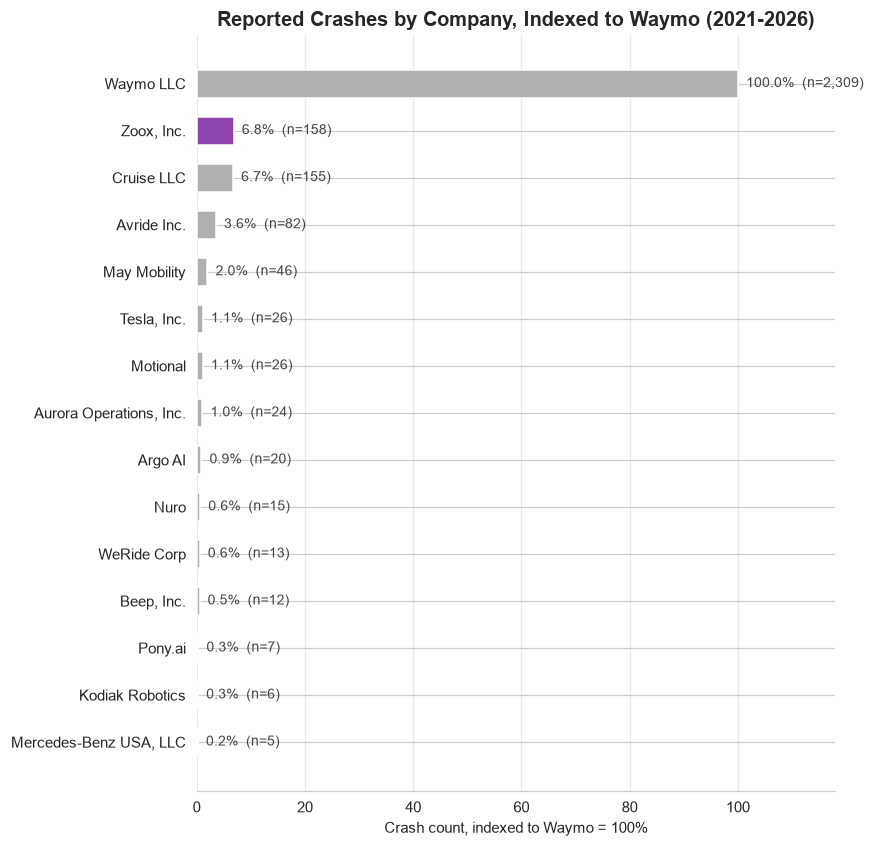

Reporting Entity
Waymo LLC                  2309
Zoox, Inc.                  158
Cruise LLC                  155
Avride Inc.                  82
May Mobility                 46
Motional                     26
Tesla, Inc.                  26
Aurora Operations, Inc.      24
Argo AI                      20
Nuro                         15
Name: count, dtype: int64

In [15]:
company_counts = crashes["Reporting Entity"].value_counts()

# index every company's crash count to Waymo = 100, so the chart reads on a
# plain 0-100 scale instead of raw counts - Waymo's volume no longer visually
# erases smaller operators the way a shared linear (or even log) count axis does.
waymo_count = company_counts["Waymo LLC"]
indexed = (company_counts / waymo_count * 100).sort_values(ascending=True).tail(15)

colors = [ZOOX_COLOR if idx == "Zoox, Inc." else PEER_COLOR for idx in indexed.index]
y = np.arange(len(indexed))

fig, ax = plt.subplots(figsize=(8, 0.42 * len(indexed) + 1.5))
ax.barh(y, indexed.values, color=colors, height=0.6, zorder=2)
for yi, (idx, v) in zip(y, indexed.items()):
    ax.text(v + 1.5, yi, f"{v:.1f}%  (n={company_counts[idx]:,})", va="center", fontsize=9, color="#444444")

ax.set_yticks(y)
ax.set_yticklabels(indexed.index)
ax.set_xlabel("Crash count, indexed to Waymo = 100%")
ax.set_title("Reported Crashes by Company, Indexed to Waymo (2021-2026)", fontsize=13, fontweight="bold")
ax.set_xlim(0, 118)
ax.grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)
plt.tight_layout()
plt.show()

company_counts.head(10)


### Crashes over time


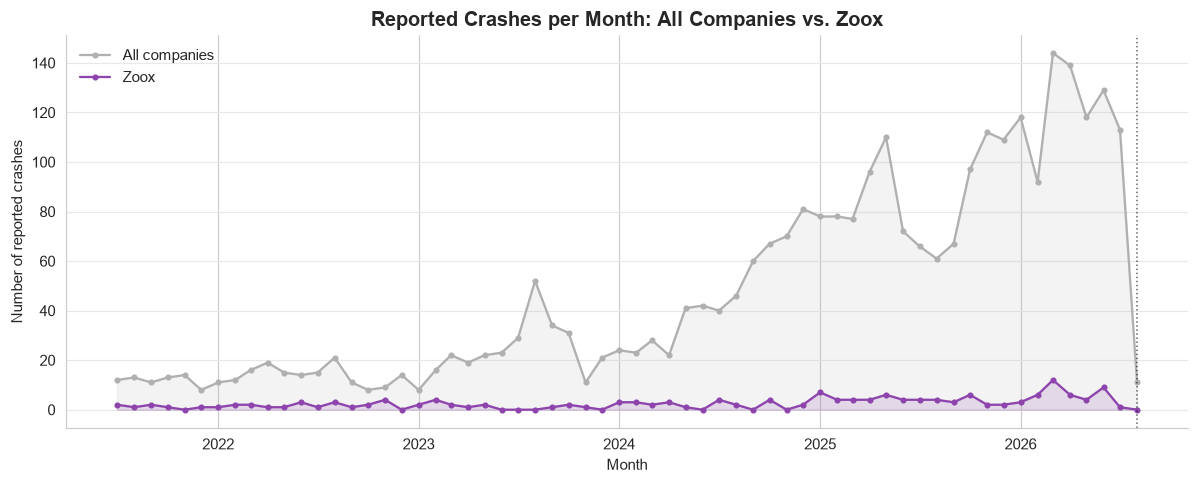

In [16]:
# drop the most recent month - reporting lag makes it look artificially low
monthly = crashes.dropna(subset=["incident_month"])
last_complete_month = monthly["incident_month"].max() - pd.DateOffset(months=1)
monthly_total = monthly.groupby("incident_month").size()
monthly_zoox = monthly[monthly["Reporting Entity"] == "Zoox, Inc."].groupby("incident_month").size()
monthly_zoox = monthly_zoox.reindex(monthly_total.index, fill_value=0)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(monthly_total.index, monthly_total.values, color=PEER_COLOR, alpha=0.15, zorder=1)
ax.fill_between(monthly_zoox.index, monthly_zoox.values, color=ZOOX_COLOR, alpha=0.15, zorder=1)
ax.plot(monthly_total.index, monthly_total.values, color=PEER_COLOR, marker="o", markersize=3, label="All companies", zorder=2)
ax.plot(monthly_zoox.index, monthly_zoox.values, color=ZOOX_COLOR, marker="o", markersize=3, label="Zoox", zorder=2)
ax.axvline(last_complete_month + pd.DateOffset(months=1), color="black", linestyle=":", linewidth=1, alpha=0.6)
ax.set_title("Reported Crashes per Month: All Companies vs. Zoox", fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Number of reported crashes")
ax.legend(frameon=False)
ax.grid(axis="y", color="#e8e8e8", linewidth=0.8, zorder=0)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()


### Crashes by state


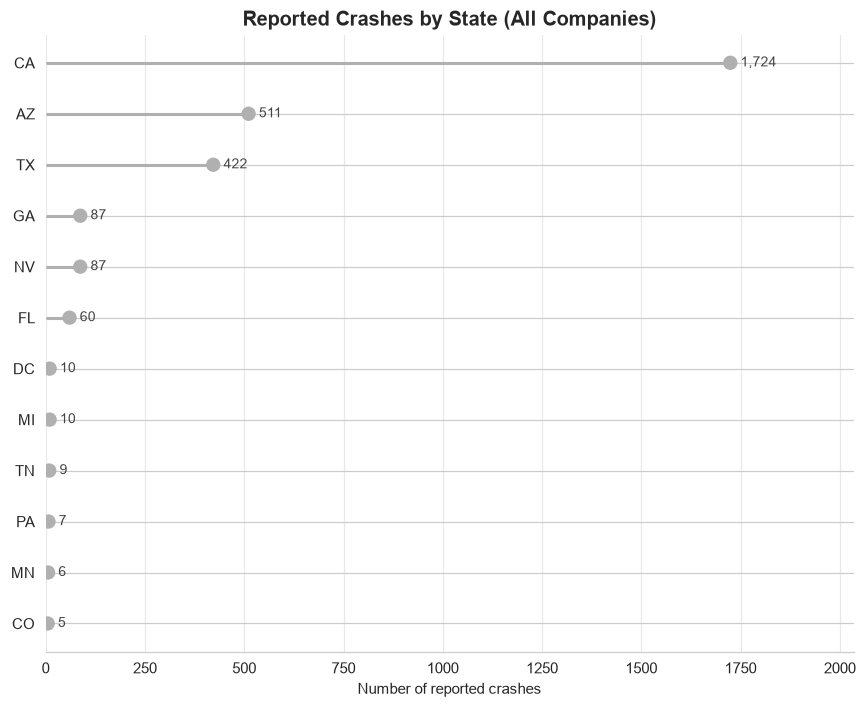

In [17]:
# industry-wide footprint, not a per-company comparison
state_counts = crashes["State"].value_counts()
plot_lollipop(state_counts, "Reported Crashes by State (All Companies)", "Number of reported crashes", top_n=12)


### Crash partner


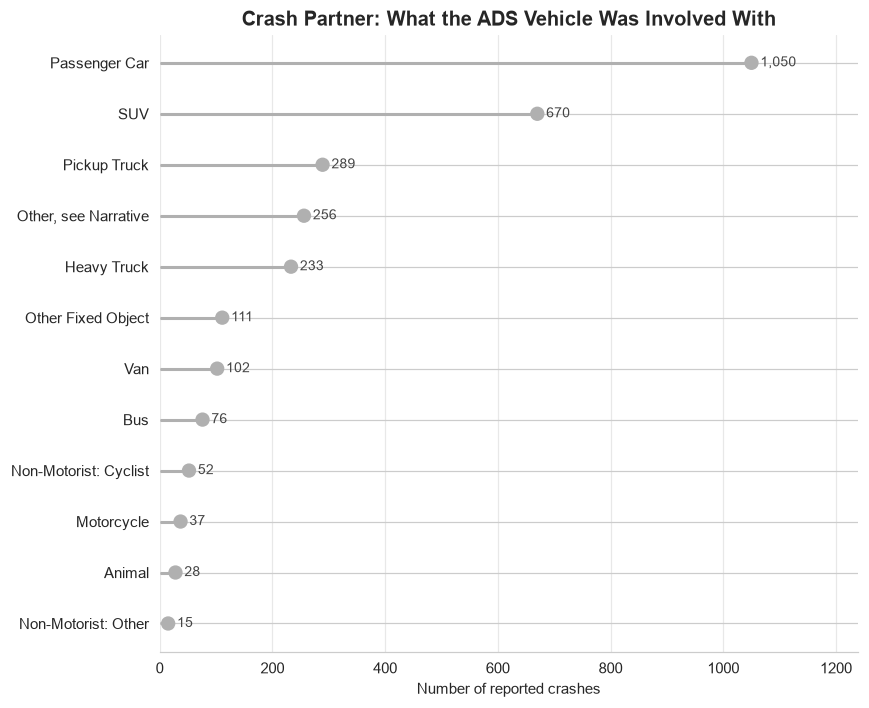

In [18]:
crash_with_counts = crashes["Crash With"].value_counts()
plot_lollipop(crash_with_counts, "Crash Partner: What the ADS Vehicle Was Involved With", "Number of reported crashes", top_n=12)


### Pre-crash movement


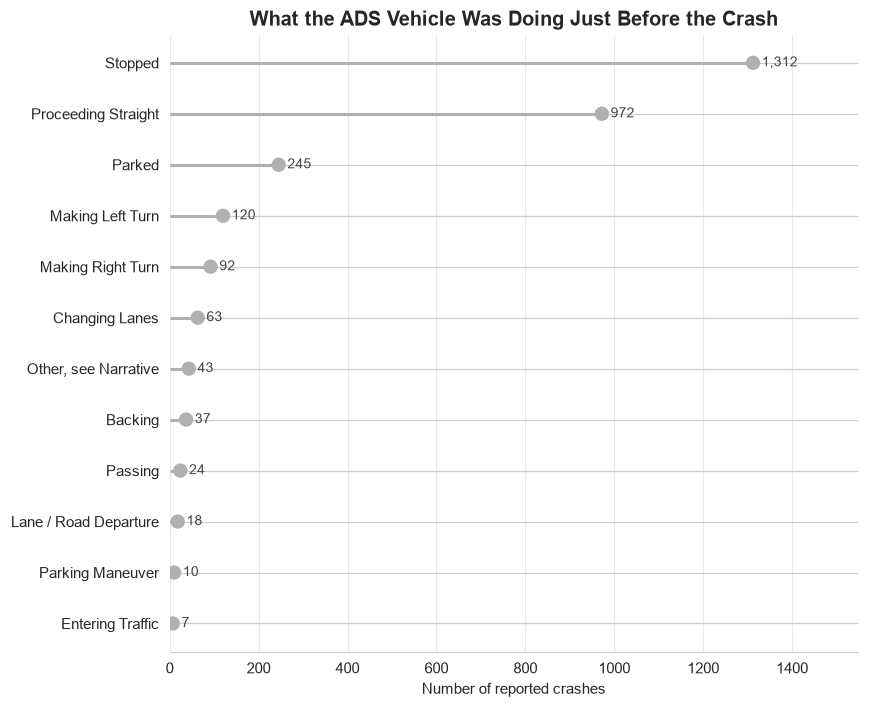

In [19]:
# SV = subject vehicle (the ADS itself), CP = crash partner
movement_counts = crashes["SV Pre-Crash Movement"].value_counts()
plot_lollipop(movement_counts, "What the ADS Vehicle Was Doing Just Before the Crash", "Number of reported crashes", top_n=12)


### Pre-crash speed


Non-null speed values: 2,942 of 2,956 (99.5%)


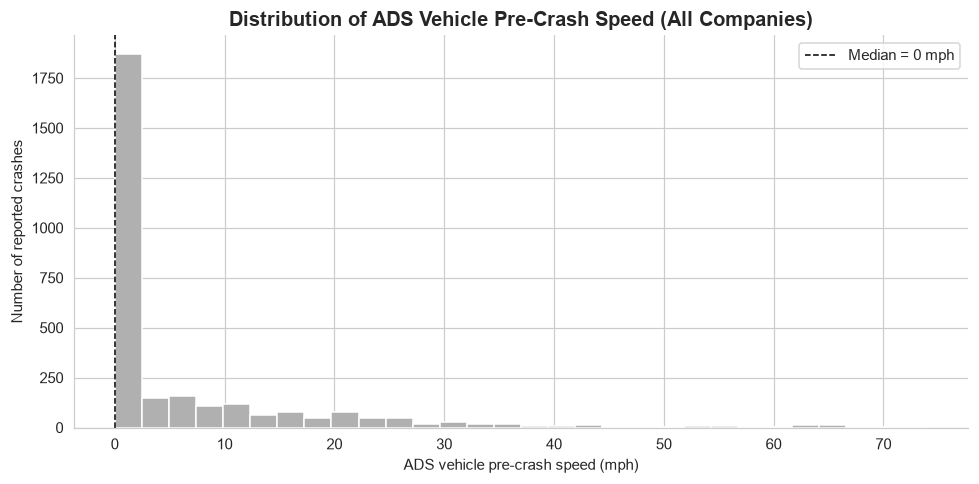

In [20]:
speed_col = "SV Precrash Speed (MPH)"
speeds = pd.to_numeric(crashes[speed_col], errors="coerce")
print(f"Non-null speed values: {speeds.notna().sum():,} of {len(speeds):,} ({speeds.notna().mean()*100:.1f}%)")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(speeds.dropna(), bins=30, color=PEER_COLOR, edgecolor="white")
ax.axvline(speeds.median(), color="black", linestyle="--", linewidth=1, label=f"Median = {speeds.median():.0f} mph")
ax.set_xlabel("ADS vehicle pre-crash speed (mph)")
ax.set_ylabel("Number of reported crashes")
ax.set_title("Distribution of ADS Vehicle Pre-Crash Speed (All Companies)", fontsize=13, fontweight="bold")
ax.legend()
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()


### Injury severity


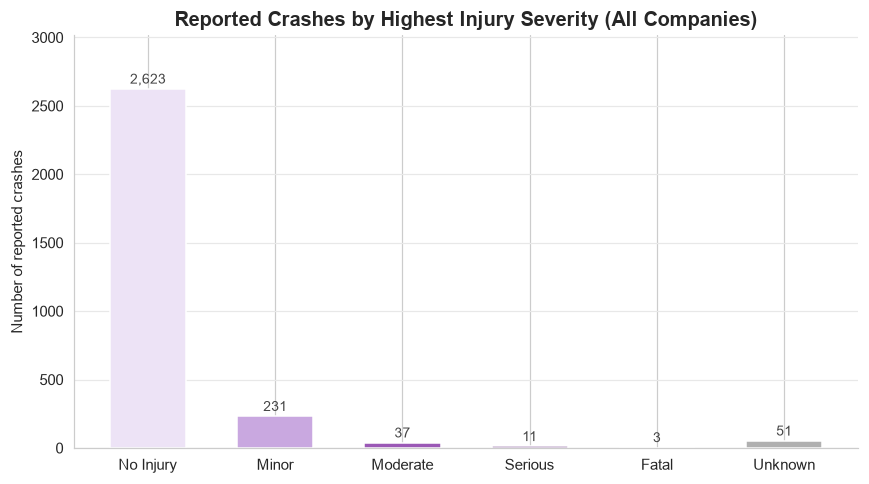

injury_severity_bucket
No Injury    2623
Minor         231
Moderate       37
Serious        11
Fatal           3
Unknown        51
Name: count, dtype: int64

In [21]:
# archive and current use different injury label sets - map both to one scale
INJURY_BUCKET_MAP = {
    "Property Damage. No Injured Reported": "No Injury",
    "No Injured Reported": "No Injury",
    "No Injuries Reported": "No Injury",
    "Minor W/O Hospitalization": "Minor",
    "Minor W/ Hospitalization": "Minor",
    "Minor": "Minor",
    "Moderate W/ Hospitalization": "Moderate",
    "Moderate W/O Hospitalization": "Moderate",
    "Moderate": "Moderate",
    "Serious W/ Hospitalization": "Serious",
    "Serious": "Serious",
    "Fatality": "Fatal",
    "Unknown": "Unknown",
}
crashes["injury_severity_bucket"] = (
    crashes["Highest Injury Severity Alleged"].map(INJURY_BUCKET_MAP).fillna("Unknown")
)

severity_order = ["No Injury", "Minor", "Moderate", "Serious", "Fatal", "Unknown"]
# sequential ramp: severity escalates light -> dark, "Unknown" stays neutral gray
SEVERITY_COLORS = {
    "No Injury": "#EDE3F6", "Minor": "#C9A8E0", "Moderate": "#9B59B6",
    "Serious": "#6C3483", "Fatal": "#3B1752", "Unknown": PEER_COLOR,
}
severity_counts = crashes["injury_severity_bucket"].value_counts().reindex(severity_order).fillna(0)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(severity_counts.index, severity_counts.values,
              color=[SEVERITY_COLORS[s] for s in severity_counts.index], width=0.6)
for bar, v in zip(bars, severity_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + severity_counts.values.max() * 0.015,
            f"{v:,.0f}", ha="center", fontsize=9, color="#444444")
ax.set_ylabel("Number of reported crashes")
ax.set_title("Reported Crashes by Highest Injury Severity (All Companies)", fontsize=13, fontweight="bold")
ax.grid(axis="y", color="#e8e8e8", linewidth=0.8, zorder=0)
ax.set_ylim(0, severity_counts.values.max() * 1.15)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()
severity_counts


### Weather conditions

Stored as one-hot flags (more than one condition can be true per crash), so we melt them into one count.

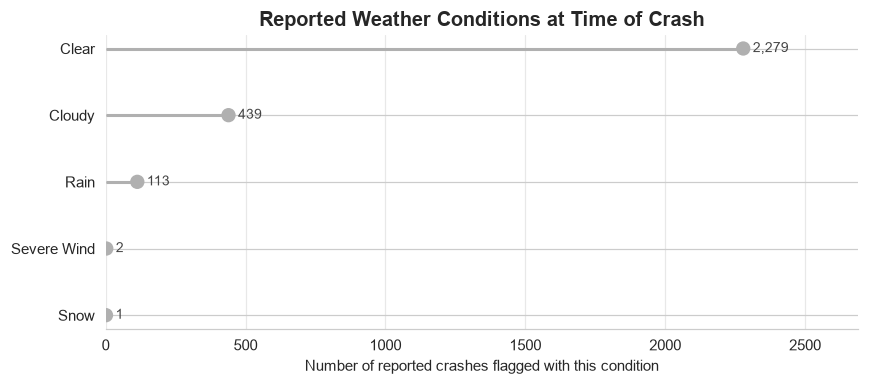

In [22]:
# weather flag columns are 'Y' when true, blank otherwise
weather_cols = [c for c in crashes.columns if c.startswith("Weather - ")]
weather_counts = (crashes[weather_cols] == "Y").sum()
weather_counts.index = [c.replace("Weather - ", "") for c in weather_counts.index]
plot_lollipop(weather_counts, "Reported Weather Conditions at Time of Crash", "Number of reported crashes flagged with this condition")


### Roadway type


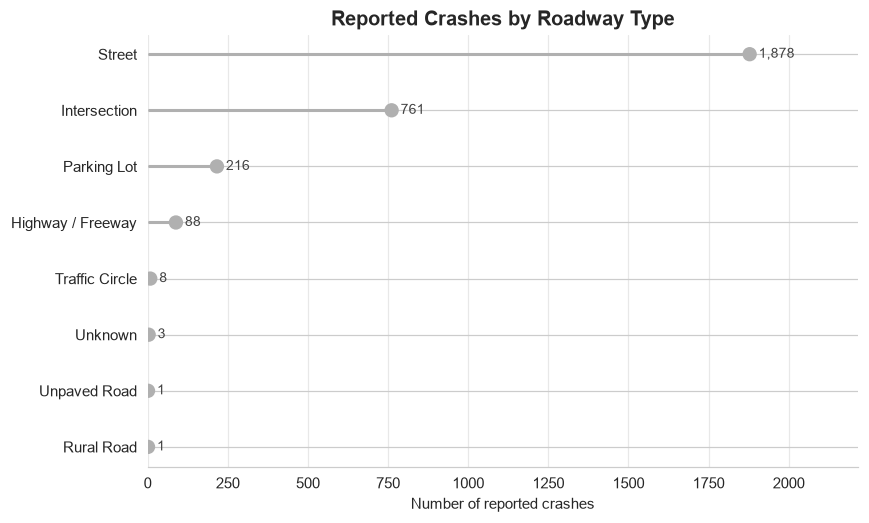

In [23]:
roadway_counts = crashes["Roadway Type"].value_counts()
plot_lollipop(roadway_counts, "Reported Crashes by Roadway Type", "Number of reported crashes")


### Lighting conditions

`Lighting` only exists in `ads_archive.csv` (2021-2025) — dropped in the 3rd Amendment schema. This chart is archive-only, not the full combined dataset.

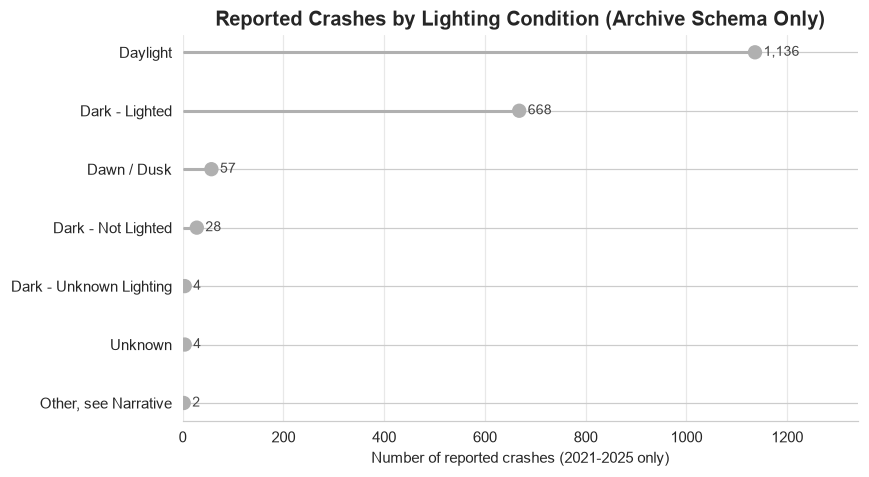

In [24]:
lighting_counts = archive_dd["Lighting"].value_counts()
plot_lollipop(lighting_counts, "Reported Crashes by Lighting Condition (Archive Schema Only)", "Number of reported crashes (2021-2025 only)")


**Takeaways:** the dominant ADS crash profile industry-wide is low-speed, no-injury, with the vehicle stopped or proceeding straight — not high-speed collisions. CA/AZ dominate geographically simply because that's where the two longest-running fleets (Waymo, Cruise) operate.

## 4. Zoox Deep Dive

Everything below filters to `Reporting Entity == "Zoox, Inc."`. We first establish what "Zoox" actually is today - two different vehicle programs, not one - then look at where, when, and how its crashes happen before comparing to peers in Section 5.


In [25]:
zoox = crashes[crashes["Reporting Entity"] == "Zoox, Inc."].copy()
print(f"Zoox: {len(zoox):,} unique reported crashes ({len(zoox)/len(crashes)*100:.1f}% of the combined dataset)")


Zoox: 158 unique reported crashes (5.3% of the combined dataset)


### Vehicle Type: Test Fleet vs. Robotaxi

"Zoox" in NHTSA's filings is not one vehicle program. Two different fleets report crashes under the same `Reporting Entity`:

- **Highlander test fleet (Zoox self-driving software, safety operator onboard):** modified Toyota Highlanders running Zoox's automated driving system (ADS), with a trained safety operator in the driver's seat, used for on-road development and data collection.
- **Zoox robotaxi (driverless, no operator):** the purpose-built vehicle with no steering wheel, now carrying riders in limited commercial service.

We classify by `Make` alone - every Toyota-make row is the Highlander test fleet, every Zoox-make row is the robotaxi. That's simpler and more complete than matching on `Model` text: a few rows have inconsistent `Model` labels (a data-entry value of "111324" for a Highlander, or the older "sedan" label for the robotaxi), and both are still classified correctly by `Make` alone.

**Why these show up in NHTSA's data at all:** NHTSA's Standing General Order requires a crash report whenever a vehicle's automated driving system was engaged in the moments before the crash - regardless of whether a trained human safety operator was also present. That's why the Highlander test fleet is reported here even with an operator onboard: it's still an ADS-engaged crash, not a conventional human-driven one.


In [26]:
HIGHLANDER_LABEL = "Highlander (Zoox software + safety operator)"
ROBOTAXI_LABEL = "Zoox robotaxi"

def classify_zoox_vehicle(row):
    make = str(row["Make"]).strip().upper()
    if make == "TOYOTA":
        return HIGHLANDER_LABEL
    if make == "ZOOX":
        return ROBOTAXI_LABEL
    return "Other/unclear"

zoox["zoox_vehicle"] = zoox.apply(classify_zoox_vehicle, axis=1)
vehicle_counts = zoox["zoox_vehicle"].value_counts()
print(vehicle_counts)

n_unclear = int(vehicle_counts.get("Other/unclear", 0))
print(f"\nRows that don't classify as either fleet by Make alone: {n_unclear}")


zoox_vehicle
Highlander (Zoox software + safety operator)    110
Zoox robotaxi                                    48
Name: count, dtype: int64

Rows that don't classify as either fleet by Make alone: 0


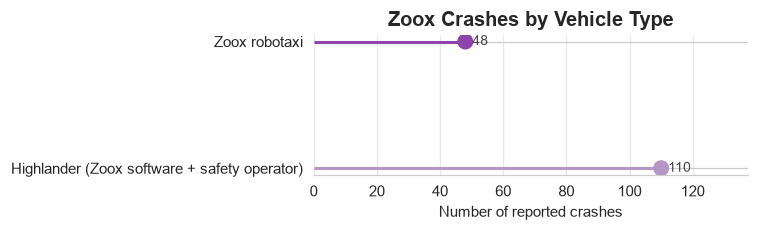

In [27]:
VEHICLE_COLORS = {HIGHLANDER_LABEL: "#B497C7", ROBOTAXI_LABEL: ZOOX_COLOR}

fig, ax = plt.subplots(figsize=(7, 2.2))
order = [v for v in VEHICLE_COLORS if v in vehicle_counts.index]
y = np.arange(len(order))
ax.hlines(y, 0, vehicle_counts[order].values, color=[VEHICLE_COLORS[v] for v in order], linewidth=2, zorder=2)
ax.scatter(vehicle_counts[order].values, y, color=[VEHICLE_COLORS[v] for v in order], s=90, zorder=3)
for yi, v in zip(y, vehicle_counts[order].values):
    ax.text(v + vehicle_counts.values.max() * 0.02, yi, f"{v:,.0f}", va="center", fontsize=9, color="#444444")
ax.set_yticks(y)
ax.set_yticklabels(order)
ax.set_xlabel("Number of reported crashes")
ax.set_title("Zoox Crashes by Vehicle Type", fontsize=13, fontweight="bold")
ax.set_xlim(0, vehicle_counts.values.max() * 1.25)
ax.grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)
plt.tight_layout()
plt.show()


In [28]:
# confirm the classification against an independent field: Driver / Operator
# Type should show the Highlander fleet as operator-supervised and the
# robotaxi as having no operator type recorded (there isn't one).
driver_type_display = zoox["Driver / Operator Type"].fillna("Not recorded (no operator)")
pd.crosstab(zoox["zoox_vehicle"], driver_type_display)


Driver / Operator Type,In-Vehicle (Commercial / Test),Not recorded (no operator),"Other, see Narrative",Remote (Commercial / Test)
zoox_vehicle,,,,
Highlander (Zoox software + safety operator),110,0,0,0
Zoox robotaxi,0,46,1,1


The crosstab confirms the classification from an independent field: all 110 Highlander rows show an in-vehicle operator (`In-Vehicle (Commercial / Test)`), and 46 of 48 robotaxi rows have no operator type recorded at all - consistent with "driverless." The 2 exceptions are a remote-assistance case (`Remote (Commercial / Test)`) and one logged as `Other, see Narrative` - edge cases, not a contradiction of the Make-based classification.


### Crashes over time


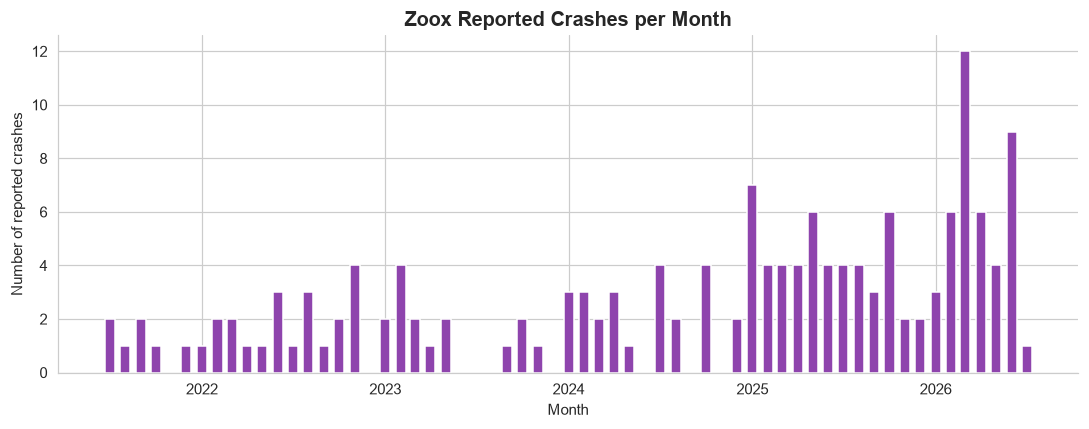

In [29]:
zoox_monthly = zoox.dropna(subset=["incident_month"]).groupby("incident_month").size()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(zoox_monthly.index, zoox_monthly.values, width=20, color=ZOOX_COLOR)
ax.set_title("Zoox Reported Crashes per Month", fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Number of reported crashes")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()


### Fleet Transition: Test Fleet to Robotaxi Over Time


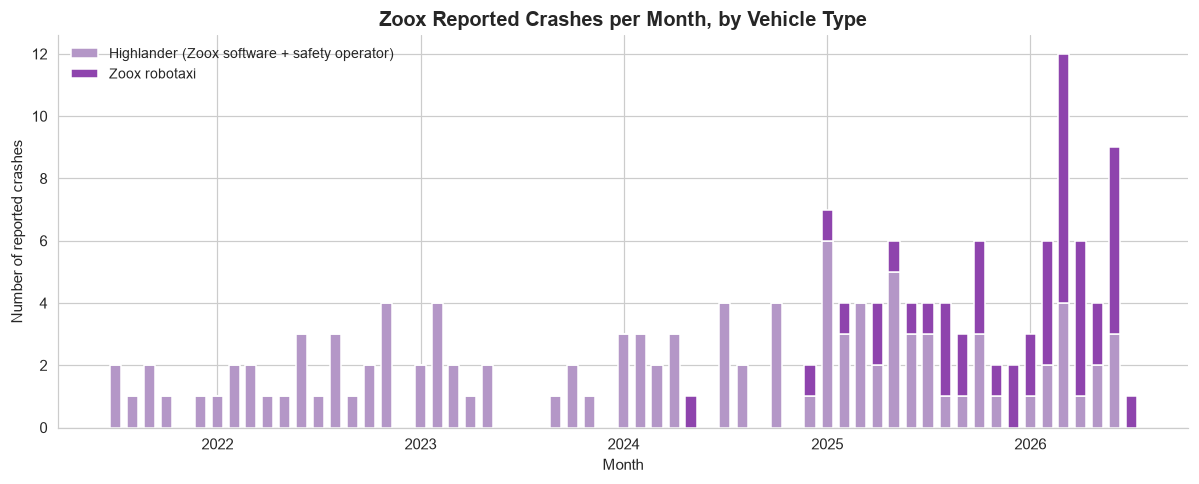

First month robotaxi crashes outnumber Highlander crashes: 2024-05

zoox_vehicle    Highlander (Zoox software + safety operator)  Zoox robotaxi
incident_month                                                             
2025-12-01                                                 0              2
2026-01-01                                                 1              2
2026-02-01                                                 2              4
2026-03-01                                                 4              8
2026-04-01                                                 1              5
2026-05-01                                                 2              2
2026-06-01                                                 3              6
2026-07-01                                                 0              1


In [30]:
zoox_monthly_by_vehicle = (
    zoox.dropna(subset=["incident_month"])
    .groupby(["incident_month", "zoox_vehicle"])
    .size()
    .unstack(fill_value=0)
)
veh_order = [v for v in VEHICLE_COLORS if v in zoox_monthly_by_vehicle.columns]
zoox_monthly_by_vehicle = zoox_monthly_by_vehicle[veh_order]

fig, ax = plt.subplots(figsize=(11, 4.5))
bottom = np.zeros(len(zoox_monthly_by_vehicle))
for veh in veh_order:
    ax.bar(zoox_monthly_by_vehicle.index, zoox_monthly_by_vehicle[veh].values, bottom=bottom,
           width=20, color=VEHICLE_COLORS[veh], label=veh)
    bottom += zoox_monthly_by_vehicle[veh].values
ax.set_title("Zoox Reported Crashes per Month, by Vehicle Type", fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Number of reported crashes")
ax.legend(frameon=False, fontsize=9)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

# first month the robotaxi has more reported crashes than the Highlander fleet
crossover = zoox_monthly_by_vehicle[zoox_monthly_by_vehicle[ROBOTAXI_LABEL] > zoox_monthly_by_vehicle[HIGHLANDER_LABEL]]
if len(crossover):
    print(f"First month robotaxi crashes outnumber Highlander crashes: {crossover.index[0].strftime('%Y-%m')}")
else:
    print("No month yet where robotaxi crashes outnumber Highlander crashes.")
print()
print(zoox_monthly_by_vehicle.tail(8))


Robotaxi crashes first outnumber Highlander crashes in a given month in May 2024, and in the most recent months on record the robotaxi consistently accounts for as many or more crashes than the Highlander fleet - though Highlander crashes continue to appear every month, meaning the test fleet is still active alongside commercial robotaxi service, not retired.


### Crash locations


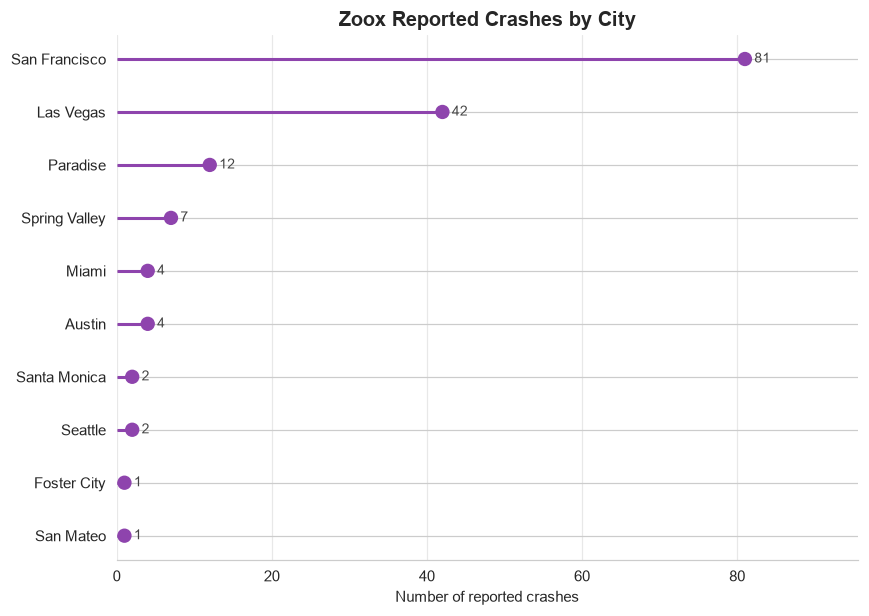

In [31]:
zoox_city_counts = zoox["City"].value_counts().head(10)
plot_lollipop(zoox_city_counts, "Zoox Reported Crashes by City", "Number of reported crashes", base_color=ZOOX_COLOR)


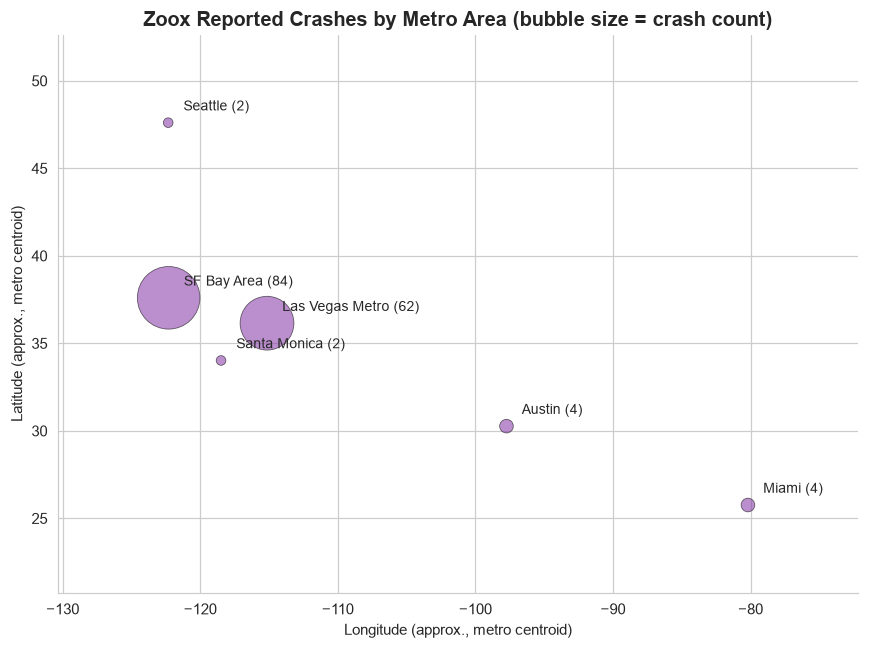

In [32]:
# lat/long are redacted dataset-wide, so we approximate with public centroids.
# Nearby suburbs (e.g. Menlo Park, Foster City) sit too close together to label
# individually at this zoom, so we roll them up into their metro area first -
# simpler to read and the business-relevant unit anyway ("which metro", not
# "which suburb").
METRO_MAP = {
    "San Francisco": "SF Bay Area", "Menlo Park": "SF Bay Area",
    "Foster City": "SF Bay Area", "San Mateo": "SF Bay Area",
    "Las Vegas": "Las Vegas Metro", "Paradise": "Las Vegas Metro",
    "Spring Valley": "Las Vegas Metro", "Winchester": "Las Vegas Metro",
}
METRO_COORDS = {
    "SF Bay Area": (37.6, -122.3),
    "Las Vegas Metro": (36.15, -115.15),
    "Austin": (30.2672, -97.7431),
    "Miami": (25.7617, -80.1918),
    "Seattle": (47.6062, -122.3321),
    "Santa Monica": (34.0195, -118.4912),
}

zoox_city_raw = zoox["City"].value_counts().rename_axis("city").reset_index(name="crash_count")
zoox_city_raw["area"] = zoox_city_raw["city"].map(METRO_MAP).fillna(zoox_city_raw["city"])
zoox_geo = zoox_city_raw.groupby("area", as_index=False)["crash_count"].sum()
zoox_geo["lat"] = zoox_geo["area"].map(lambda a: METRO_COORDS.get(a, (None, None))[0])
zoox_geo["lon"] = zoox_geo["area"].map(lambda a: METRO_COORDS.get(a, (None, None))[1])
zoox_geo = zoox_geo.dropna(subset=["lat", "lon"]).sort_values("crash_count", ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    zoox_geo["lon"], zoox_geo["lat"],
    s=zoox_geo["crash_count"] * 20, color=ZOOX_COLOR, alpha=0.6, edgecolor="black", linewidth=0.5, zorder=2,
)
for _, row in zoox_geo.iterrows():
    ax.annotate(f"{row['area']} ({row['crash_count']:.0f})", (row["lon"], row["lat"]),
                textcoords="offset points", xytext=(10, 8), fontsize=9)
ax.set_xlabel("Longitude (approx., metro centroid)")
ax.set_ylabel("Latitude (approx., metro centroid)")
ax.set_title("Zoox Reported Crashes by Metro Area (bubble size = crash count)", fontsize=13, fontweight="bold")
ax.set_xlim(zoox_geo["lon"].min() - 8, zoox_geo["lon"].max() + 8)
ax.set_ylim(zoox_geo["lat"].min() - 5, zoox_geo["lat"].max() + 5)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()


### City Comparison: San Francisco vs. Las Vegas

Zoox operates commercial service in two metro areas. If a crash scenario is concentrated in one city and not the other, that matters directly for planning validation ahead of a launch in a *new* city, since a new market won't automatically inherit whichever city's pattern is driving today's aggregate number. Counts per city are small, so this is read descriptively, not as a statistical test.


SF Bay Area: 84 crashes | Las Vegas Metro: 62 crashes | outside both: 12 crashes
SF Bay Area movement %:
SV Pre-Crash Movement
Proceeding Straight     36.9
Stopped                 41.7
Making Right Turn        9.5
Making Left Turn         6.0
Changing Lanes           2.4
Other, see Narrative     2.4
Name: proportion, dtype: float64

Las Vegas Metro movement %:
SV Pre-Crash Movement
Proceeding Straight     38.7
Stopped                 30.6
Making Right Turn       17.7
Making Left Turn         6.5
Changing Lanes           1.6
Other, see Narrative     0.0
Name: proportion, dtype: float64


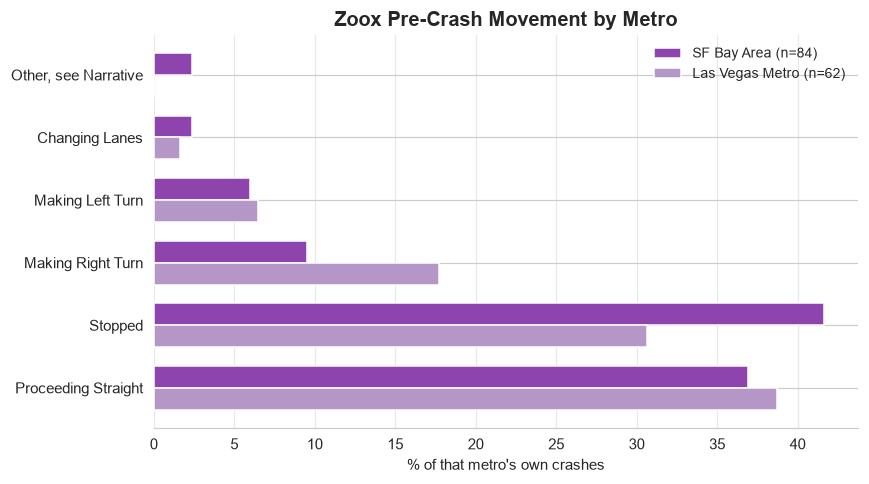

In [33]:
zoox_geo_scenario = zoox.copy()
zoox_geo_scenario["metro"] = zoox_geo_scenario["City"].map(METRO_MAP)
zoox_geo_scenario = zoox_geo_scenario[zoox_geo_scenario["metro"].isin(["SF Bay Area", "Las Vegas Metro"])]

metro_counts = zoox_geo_scenario["metro"].value_counts()
n_sf = int(metro_counts.get("SF Bay Area", 0))
n_lv = int(metro_counts.get("Las Vegas Metro", 0))
print(f"SF Bay Area: {n_sf} crashes | Las Vegas Metro: {n_lv} crashes "
      f"| outside both: {len(zoox) - n_sf - n_lv} crashes")

top_moves_city = zoox_geo_scenario["SV Pre-Crash Movement"].value_counts().head(6).index
sf_mv = zoox_geo_scenario.loc[zoox_geo_scenario["metro"] == "SF Bay Area", "SV Pre-Crash Movement"]\
    .value_counts(normalize=True).reindex(top_moves_city).fillna(0) * 100
lv_mv = zoox_geo_scenario.loc[zoox_geo_scenario["metro"] == "Las Vegas Metro", "SV Pre-Crash Movement"]\
    .value_counts(normalize=True).reindex(top_moves_city).fillna(0) * 100

print("SF Bay Area movement %:")
print(sf_mv.round(1))
print("\nLas Vegas Metro movement %:")
print(lv_mv.round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(top_moves_city))
bar_h = 0.35
ax.barh(y + bar_h / 2, sf_mv.values, height=bar_h, color=ZOOX_COLOR, label=f"SF Bay Area (n={n_sf})")
ax.barh(y - bar_h / 2, lv_mv.values, height=bar_h, color="#B497C7", label=f"Las Vegas Metro (n={n_lv})")
ax.set_yticks(y)
ax.set_yticklabels(top_moves_city)
ax.set_xlabel("% of that metro's own crashes")
ax.set_title("Zoox Pre-Crash Movement by Metro", fontsize=13, fontweight="bold")
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)
plt.tight_layout()
plt.show()


Right-turn crashes are close to twice as common in Las Vegas (17.7% of that metro's Zoox crashes) as in San Francisco (9.5%), while "Stopped" crashes are more common in SF (41.7%) than Las Vegas (30.6%). With only 62-84 crashes per metro this is descriptive, not a statistical test - but if the pattern holds, it suggests road-network design (Las Vegas's wide arterial intersections vs. SF's dense stop-and-go grid) shapes the crash mix as much as the vehicle itself, which matters for predicting a new city's profile before it has any crash history of its own.


### Crash Scenario Overview (Zoox Only)


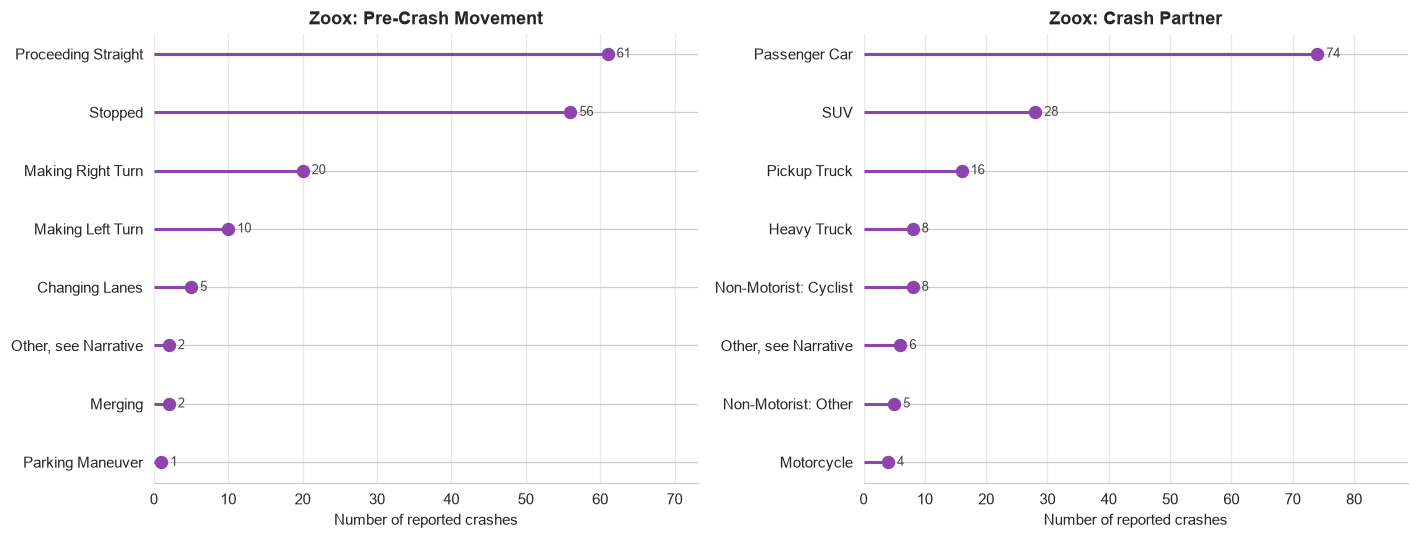

In [34]:
def lollipop_on_ax(ax, counts, title, xlabel, color=ZOOX_COLOR, top_n=8):
    counts = counts.sort_values(ascending=True).tail(top_n)
    y = np.arange(len(counts))
    ax.hlines(y, 0, counts.values, color=color, linewidth=2, zorder=2)
    ax.scatter(counts.values, y, color=color, s=60, zorder=3)
    for yi, v in zip(y, counts.values):
        ax.text(v + counts.values.max() * 0.02, yi, f"{v:,.0f}", va="center", fontsize=8.5, color="#444444")
    ax.set_yticks(y)
    ax.set_yticklabels(counts.index.astype(str))
    ax.set_xlabel(xlabel)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlim(0, counts.values.max() * 1.2)
    ax.grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.tick_params(left=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
mv = zoox["SV Pre-Crash Movement"].value_counts()
lollipop_on_ax(axes[0], mv, "Zoox: Pre-Crash Movement", "Number of reported crashes")
cw = zoox["Crash With"].value_counts()
lollipop_on_ax(axes[1], cw, "Zoox: Crash Partner", "Number of reported crashes")
plt.tight_layout()
plt.show()


### Contact area (struck vs. struck by, inferred)

No direct fault field exists. As a proxy: rear contact area while `Stopped`/`Parked`/`Proceeding Straight` is consistent with being struck from behind — an inference, not a stated fact.

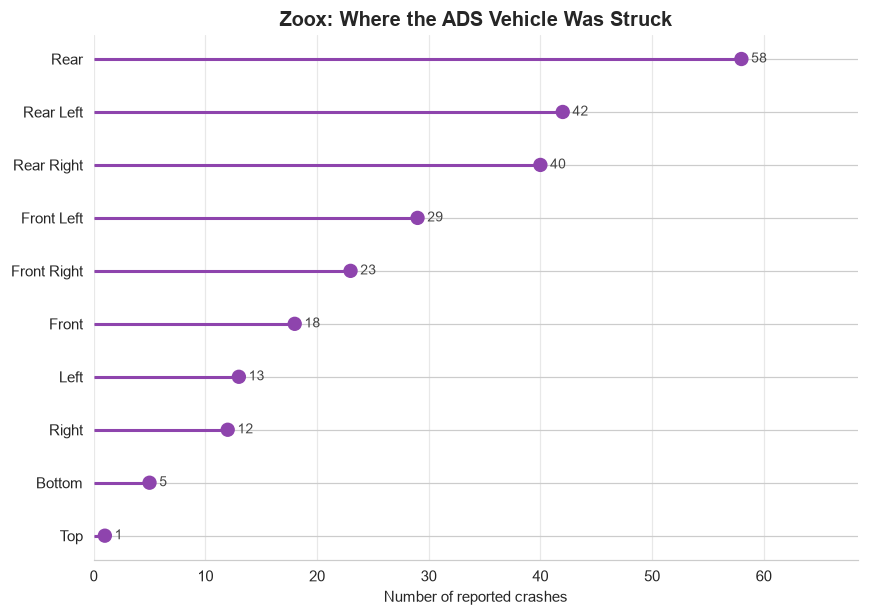

In [35]:
sv_contact_cols = [c for c in zoox.columns if c.startswith("SV Contact Area - ") and "Unknown" not in c]
sv_contact_counts = (zoox[sv_contact_cols] == "Y").sum()
sv_contact_counts.index = [c.replace("SV Contact Area - ", "") for c in sv_contact_counts.index]
plot_lollipop(sv_contact_counts, "Zoox: Where the ADS Vehicle Was Struck", "Number of reported crashes", base_color=ZOOX_COLOR)


### Speed and injury outcomes


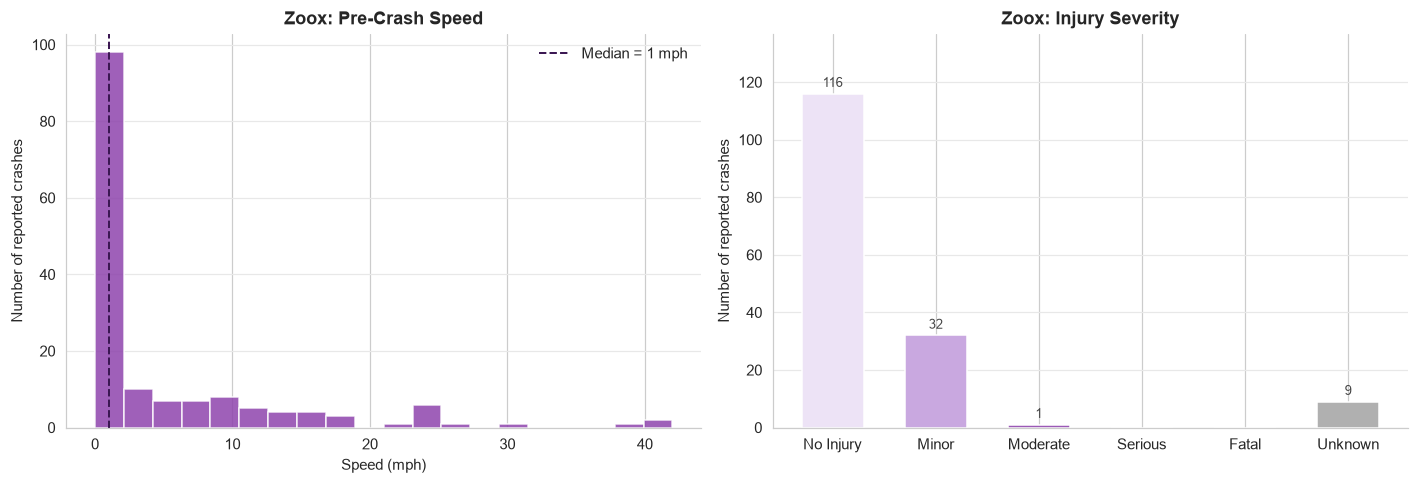

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

zoox_speeds = pd.to_numeric(zoox[speed_col], errors="coerce").dropna()
axes[0].hist(zoox_speeds, bins=20, color=ZOOX_COLOR, edgecolor="white", alpha=0.85)
axes[0].axvline(zoox_speeds.median(), color="#3B1752", linestyle="--", linewidth=1.3,
                 label=f"Median = {zoox_speeds.median():.0f} mph")
axes[0].set_title("Zoox: Pre-Crash Speed", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Speed (mph)")
axes[0].set_ylabel("Number of reported crashes")
axes[0].legend(frameon=False)
axes[0].grid(axis="y", color="#e8e8e8", linewidth=0.8, zorder=0)

zoox_severity = zoox["injury_severity_bucket"].value_counts().reindex(severity_order).fillna(0)
bars = axes[1].bar(zoox_severity.index, zoox_severity.values,
                    color=[SEVERITY_COLORS[s] for s in zoox_severity.index], width=0.6)
for bar, v in zip(bars, zoox_severity.values):
    if v > 0:
        axes[1].text(bar.get_x() + bar.get_width() / 2, v + zoox_severity.values.max() * 0.02,
                      f"{v:,.0f}", ha="center", fontsize=8.5, color="#444444")
axes[1].set_title("Zoox: Injury Severity", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Number of reported crashes")
axes[1].grid(axis="y", color="#e8e8e8", linewidth=0.8, zorder=0)
axes[1].set_ylim(0, zoox_severity.values.max() * 1.18)

for ax in axes:
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()


### Narrative Keyword Tagging

NHTSA's `Narrative` field is free text, redacted for some reports as confidential business information. We tag it for a handful of simple keyword patterns below - this is keyword matching on the raw text, not NLP or full text analysis, so it undercounts anything phrased differently than the literal keyword and can't distinguish context (e.g., "braked hard to avoid X" vs. "was unable to brake in time").


In [37]:
NARRATIVE_PATTERNS = {
    "rear-ended": r"rear[- ]?end",
    "disengaged": r"disengag",
    "manual mode": r"manual mode",
    "double-parked": r"double[- ]?park",
    "braked": r"brak",
}

narrative = zoox["Narrative"].astype(str)
is_redacted = narrative.str.contains("REDACTED", case=False, na=False)

tag_rows = []
for vt in VEHICLE_COLORS:
    mask = zoox["zoox_vehicle"] == vt
    sub, sub_redacted = narrative[mask], is_redacted[mask]
    row = {"vehicle": vt, "n": int(mask.sum()), "Redacted": int(sub_redacted.sum())}
    for label, pattern in NARRATIVE_PATTERNS.items():
        row[label] = int(sub[~sub_redacted].str.contains(pattern, case=False, regex=True, na=False).sum())
    tag_rows.append(row)

narrative_tags = pd.DataFrame(tag_rows).set_index("vehicle")
narrative_tags


,n,Redacted,rear-ended,disengaged,manual mode,double-parked,braked
vehicle,,,,,,,
Highlander (Zoox software + safety operator),110,1,31,59,14,2,32
Zoox robotaxi,48,1,15,0,0,1,26


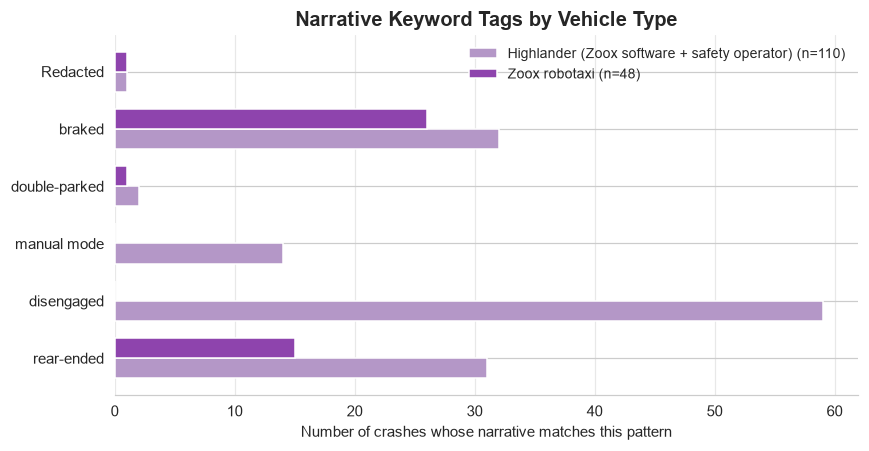

In [38]:
fig, ax = plt.subplots(figsize=(8, 4.2))
keywords = list(NARRATIVE_PATTERNS.keys()) + ["Redacted"]
y = np.arange(len(keywords))
bar_h = 0.35
veh_list = list(VEHICLE_COLORS.keys())
for i, vt in enumerate(veh_list):
    vals = narrative_tags.loc[vt, keywords].values
    offset = (i - (len(veh_list) - 1) / 2) * bar_h
    ax.barh(y + offset, vals, height=bar_h, color=VEHICLE_COLORS[vt],
            label=f"{vt} (n={narrative_tags.loc[vt, 'n']})")
ax.set_yticks(y)
ax.set_yticklabels(keywords)
ax.set_xlabel("Number of crashes whose narrative matches this pattern")
ax.set_title("Narrative Keyword Tags by Vehicle Type", fontsize=13, fontweight="bold")
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)
plt.tight_layout()
plt.show()


"Disengaged" (59 of 110) and "manual mode" (14 of 110) appear only in Highlander narratives - mechanically, the robotaxi has no human driver who could disengage into manual mode, so a 0% rate there confirms the vehicle-type split rather than contradicting it. "Braked" appears in a slight majority of both fleets' narratives (29.1% Highlander, 54.2% robotaxi) and "rear-ended" at similar rates in both (28.2% vs. 31.3%, not tested statistically here - this is keyword matching, not a controlled comparison).


**Takeaways:** Zoox's 158 crashes split 110 Highlander test fleet / 48 robotaxi, and the robotaxi has outnumbered the Highlander fleet in monthly crash volume since May 2024 - though the test fleet is still active, not retired. Crashes concentrate in two metros, SF Bay Area (84) and Las Vegas (62), with Las Vegas showing nearly double SF's right-turn crash share (17.7% vs. 9.5%) - a first hint that road network, not just the vehicle, shapes the scenario mix. Narrative text independently confirms the vehicle split: "disengaged" and "manual mode" appear only in Highlander crashes, since the robotaxi has no driver to disengage. We quantify the Zoox-vs-Waymo scenario differences next.


## 5. Zoox vs. Peers

Proportions within each company's own crash mix, with 95% Wilson confidence intervals and Fisher's exact / chi-square tests - never raw counts, since fleet size and mileage differ enormously between companies. We start with a data-driven ranking of which scenarios are most over-represented in Zoox's crashes relative to Waymo, then drill into the specific scenarios that ranking surfaces.


In [39]:
from scipy import stats

def wilson_ci(successes, n, confidence=0.95):
    """Wilson score interval for a binomial proportion — more reliable than the
    normal approximation at small n or extreme proportions, both of which we
    have here (some companies only have a few dozen crashes)."""
    if n == 0:
        return (np.nan, np.nan, np.nan)
    z = stats.norm.ppf(1 - (1 - confidence) / 2)
    phat = successes / n
    denom = 1 + z**2 / n
    center = (phat + z**2 / (2 * n)) / denom
    half_width = (z * np.sqrt(phat * (1 - phat) / n + z**2 / (4 * n**2))) / denom
    return (phat, max(0, center - half_width), min(1, center + half_width))

def two_proportion_chisq(df, group_col, flag_col, group_a, group_b):
    """Chi-square test of independence on the 2x2 table: does `flag_col`
    depend on which of the two groups a crash belongs to?"""
    sub = df[df[group_col].isin([group_a, group_b])]
    table = pd.crosstab(sub[group_col], sub[flag_col])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    return chi2, p, table


### Crash Scenario Ranking: Zoox vs. Waymo

To answer "which scenarios should validation prioritize," we build a single `crash_scenario` field - pre-crash movement + crash partner, collapsed to "stopped/parked, rear-ended by X" when the struck-from-behind pattern applies - and rank scenarios by how over-represented they are in Zoox's crashes vs. Waymo's. We only score scenarios with at least 5 Zoox crashes, so the ranking isn't driven by one-off combinations.


                                   scenario  zoox_n  zoox_pct    zoox_ci  waymo_n  waymo_pct  ratio  p_fisher
          Making Right Turn + Passenger Car      10      6.33 [3.5-11.3]       15       0.65   9.74  1.24e-06
           Making Left Turn + Passenger Car       5      3.16  [1.4-7.2]       31       1.34   2.36    0.0763
Stopped/parked, rear-ended by Passenger Car      21      13.3 [8.9-19.5]      141       6.11   2.18   0.00132
                  Proceeding Straight + SUV      18      11.4 [7.3-17.3]      147       6.37   1.79    0.0204
 Stopped/parked, rear-ended by Pickup Truck       5      3.16  [1.4-7.2]       41       1.78   1.78     0.214
        Proceeding Straight + Passenger Car      23      14.6 [9.9-20.9]      225       9.74   1.49    0.0559
                    Stopped + Passenger Car      10      6.33 [3.5-11.3]      280       12.1  0.522    0.0291


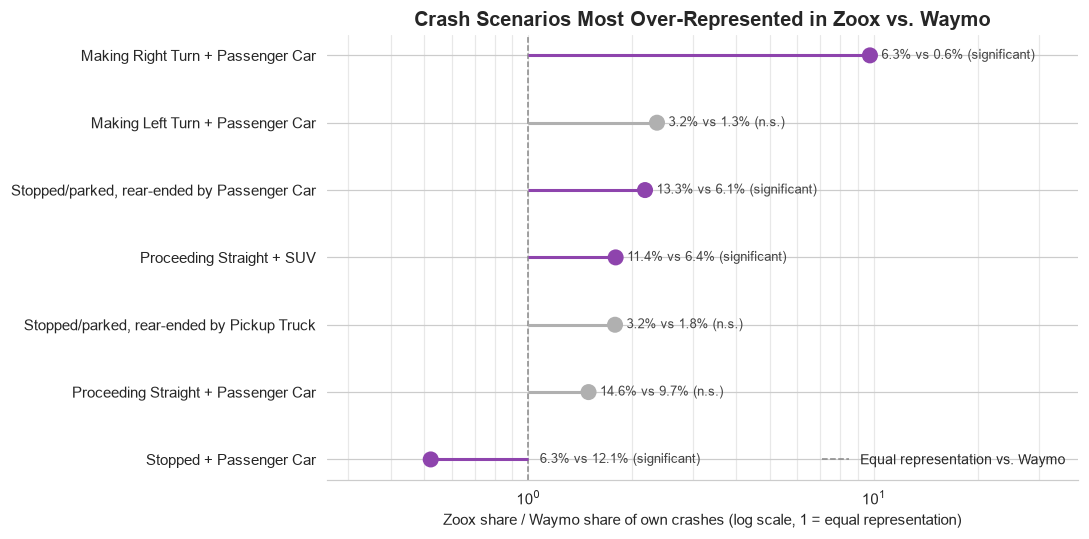

In [40]:
def flag_rear_ended(df):
    return df["SV Pre-Crash Movement"].isin(["Stopped", "Parked"]) & (df["SV Contact Area - Rear"] == "Y")

def build_scenario(df):
    flag = flag_rear_ended(df)
    scenario = df["SV Pre-Crash Movement"] + " + " + df["Crash With"]
    return scenario.mask(flag, "Stopped/parked, rear-ended by " + df["Crash With"])

waymo = crashes[crashes["Reporting Entity"] == "Waymo LLC"].copy()
zoox_sc = zoox.copy()
zoox_sc["crash_scenario"] = build_scenario(zoox_sc)
waymo["crash_scenario"] = build_scenario(waymo)

zoox_scenario_counts = zoox_sc["crash_scenario"].value_counts()
eligible_scenarios = zoox_scenario_counts[zoox_scenario_counts >= 5].index.tolist()

zn, wn = len(zoox_sc), len(waymo)
rows = []
for scenario in eligible_scenarios:
    zk = int((zoox_sc["crash_scenario"] == scenario).sum())
    wk = int((waymo["crash_scenario"] == scenario).sum())
    z_phat, z_lo, z_hi = wilson_ci(zk, zn)
    w_phat, w_lo, w_hi = wilson_ci(wk, wn)
    ratio = (z_phat / w_phat) if w_phat > 0 else np.inf
    _, p = stats.fisher_exact([[zk, zn - zk], [wk, wn - wk]])
    rows.append({
        "scenario": scenario, "zoox_n": zk, "zoox_pct": z_phat * 100,
        "zoox_ci": f"[{z_lo*100:.1f}-{z_hi*100:.1f}]", "waymo_n": wk, "waymo_pct": w_phat * 100,
        "ratio": ratio, "p_fisher": p,
    })

scenario_ranking = pd.DataFrame(rows).sort_values("ratio", ascending=False).reset_index(drop=True)
pd.set_option("display.float_format", lambda x: f"{x:.3g}")
print(scenario_ranking.to_string(index=False))

# chart only the finite-ratio scenarios (a ratio of infinity, i.e. zero Waymo
# crashes of that type, can't be placed on a log axis) - any excluded here are
# called out in the printed table above.
plot_df = scenario_ranking[np.isfinite(scenario_ranking["ratio"])].sort_values("ratio", ascending=True).tail(8)

fig, ax = plt.subplots(figsize=(10, 0.5 * len(plot_df) + 1.5))
y = np.arange(len(plot_df))
colors = [ZOOX_COLOR if p < 0.05 else PEER_COLOR for p in plot_df["p_fisher"]]
ax.hlines(y, 1, plot_df["ratio"], color=colors, linewidth=2, zorder=2)
ax.scatter(plot_df["ratio"], y, color=colors, s=90, zorder=3)
ax.axvline(1, color="#888888", linestyle="--", linewidth=1, zorder=1, label="Equal representation vs. Waymo")
for yi, row in zip(y, plot_df.itertuples()):
    tag = "significant" if row.p_fisher < 0.05 else "n.s."
    ax.text(max(row.ratio, 1) * 1.08, yi, f"{row.zoox_pct:.1f}% vs {row.waymo_pct:.1f}% ({tag})",
            va="center", fontsize=8.5, color="#444444")
ax.set_yticks(y)
ax.set_yticklabels(plot_df["scenario"])
ax.set_xscale("log")
ax.set_xlabel("Zoox share / Waymo share of own crashes (log scale, 1 = equal representation)")
ax.set_title("Crash Scenarios Most Over-Represented in Zoox vs. Waymo", fontsize=13, fontweight="bold")
ax.set_xlim(plot_df["ratio"].min() * 0.5, plot_df["ratio"].max() * 4)
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0, which="both")
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)
plt.tight_layout()
plt.show()


Two scenarios are both large and statistically significant even before correcting for multiple comparisons: **"Making Right Turn + Passenger Car"** (Zoox 6.3% vs. Waymo 0.65%, a 9.7x ratio, p<0.0001) and **"Stopped/parked, rear-ended by Passenger Car"** (Zoox 13.3% vs. Waymo 6.1%, a 2.2x ratio, p=0.0013). "Proceeding Straight + SUV" is nominally significant (p=0.02) but doesn't survive correction below (see the multiple-comparisons table). One scenario is *under*-represented: plain "Stopped + Passenger Car" (not rear-ended) is less common for Zoox than Waymo (6.3% vs. 12.1%) - consistent with more of Zoox's stopped crashes specifically involving a rear-end hit, not stopped crashes generally.


### Does the Pattern Carry Over to the Robotaxi?

For each top-ranked scenario above, we compare the Highlander share to the robotaxi share directly. A scenario only "persists in the robotaxi" if the robotaxi's own share is still clearly elevated vs. Waymo (we use >=1.5x Waymo's share as the bar) and there are enough robotaxi crashes in that scenario to say anything (we require at least 5). Otherwise we call it test-fleet-only, or too small a sample to tell.


                                   scenario  highlander_pct  highlander_n  robotaxi_pct  robotaxi_n  waymo_pct                          verdict
          Making Right Turn + Passenger Car            8.18             9          2.08           1       0.65 Too few robotaxi crashes to tell
           Making Left Turn + Passenger Car            4.55             5             0           0       1.34 Too few robotaxi crashes to tell
Stopped/parked, rear-ended by Passenger Car            14.5            16          10.4           5       6.11             Persists in robotaxi
                  Proceeding Straight + SUV              10            11          14.6           7       6.37             Persists in robotaxi
 Stopped/parked, rear-ended by Pickup Truck            1.82             2          6.25           3       1.78 Too few robotaxi crashes to tell
        Proceeding Straight + Passenger Car            14.5            16          14.6           7       9.74                Mainly tes

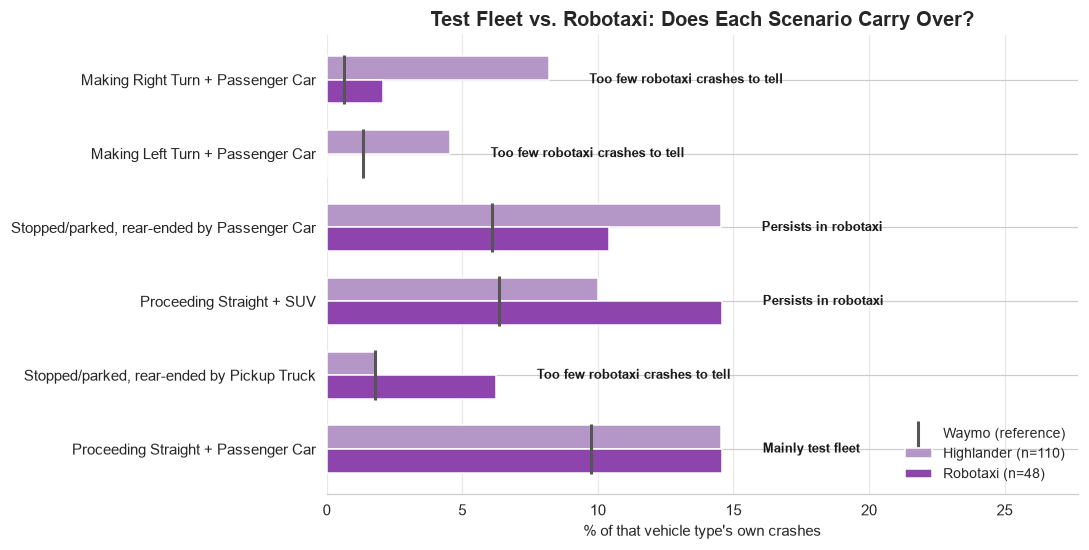

In [41]:
highlander_sc = zoox_sc[zoox_sc["zoox_vehicle"] == HIGHLANDER_LABEL]
robotaxi_sc = zoox_sc[zoox_sc["zoox_vehicle"] == ROBOTAXI_LABEL]
h_n, r_n = len(highlander_sc), len(robotaxi_sc)

top_scenarios = scenario_ranking[np.isfinite(scenario_ranking["ratio"])].head(6)

carryover_rows = []
for row in top_scenarios.itertuples():
    h_k = int((highlander_sc["crash_scenario"] == row.scenario).sum())
    r_k = int((robotaxi_sc["crash_scenario"] == row.scenario).sum())
    h_pct = h_k / h_n * 100
    r_pct = r_k / r_n * 100
    if r_k < 5:
        verdict = "Too few robotaxi crashes to tell"
    elif r_pct >= row.waymo_pct * 1.5:
        verdict = "Persists in robotaxi"
    else:
        verdict = "Mainly test fleet"
    carryover_rows.append({
        "scenario": row.scenario, "highlander_pct": h_pct, "highlander_n": h_k,
        "robotaxi_pct": r_pct, "robotaxi_n": r_k, "waymo_pct": row.waymo_pct, "verdict": verdict,
    })

carryover = pd.DataFrame(carryover_rows)
print(carryover.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 0.6 * len(carryover) + 1.5))
y = np.arange(len(carryover))[::-1]
bar_h = 0.32
ax.barh(y + bar_h / 2, carryover["highlander_pct"], height=bar_h, color="#B497C7",
        label=f"Highlander (n={h_n})", zorder=2)
ax.barh(y - bar_h / 2, carryover["robotaxi_pct"], height=bar_h, color=ZOOX_COLOR,
        label=f"Robotaxi (n={r_n})", zorder=2)
ax.scatter(carryover["waymo_pct"], y + bar_h / 2, marker="|", s=300, color="#555555", linewidth=2, zorder=3)
ax.scatter(carryover["waymo_pct"], y - bar_h / 2, marker="|", s=300, color="#555555", linewidth=2, zorder=3,
           label="Waymo (reference)")
for yi, row in zip(y, carryover.itertuples()):
    ax.text(max(row.highlander_pct, row.robotaxi_pct, row.waymo_pct) + 1.5, yi, row.verdict,
            va="center", fontsize=8.5, color="#1a1a1a", fontweight="bold")
ax.set_yticks(y)
ax.set_yticklabels(carryover["scenario"])
ax.set_xlabel("% of that vehicle type's own crashes")
ax.set_title("Test Fleet vs. Robotaxi: Does Each Scenario Carry Over?", fontsize=13, fontweight="bold")
ax.set_xlim(0, max(carryover[["highlander_pct", "robotaxi_pct"]].values.max() * 1.9, 20))
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)
plt.tight_layout()
plt.show()


Of the two statistically significant scenarios, one persists in the robotaxi and one doesn't have enough robotaxi data yet to say: **"Stopped/parked, rear-ended by Passenger Car"** persists (10.4% robotaxi vs. 6.1% Waymo), but **"Making Right Turn + Passenger Car"** has only 1 robotaxi crash so far - too few to tell if the pattern carries over. "Proceeding Straight + SUV" also persists (14.6% robotaxi vs. 6.4% Waymo). "Proceeding Straight + Passenger Car" sits right at the test-fleet/persists boundary (14.6% robotaxi is nearly identical to 14.5% Highlander, just short of our 1.5x-Waymo bar) - read that one as inconclusive rather than a clean negative.


### Vehicle-Type Behavior: Movement, Crash Partner, Speed

The scenario ranking above is a snapshot; this shows the fuller movement, crash-partner, and speed picture behind it, split by vehicle type (classification defined in Section 4).


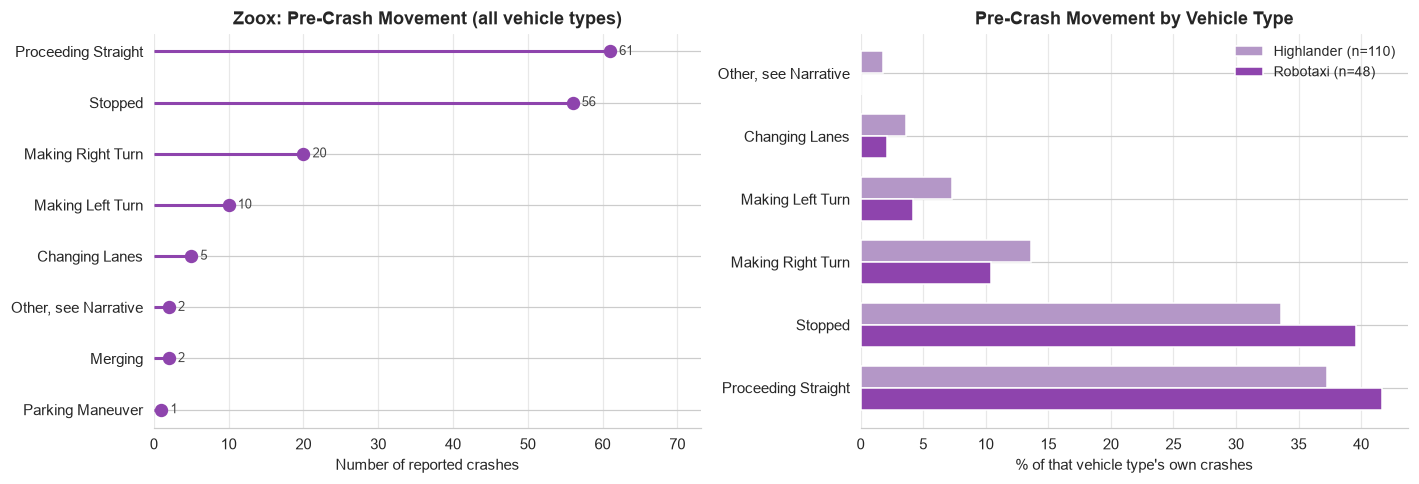

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

mv_all = zoox["SV Pre-Crash Movement"].value_counts()
lollipop_on_ax(axes[0], mv_all, "Zoox: Pre-Crash Movement (all vehicle types)", "Number of reported crashes")

top_moves = mv_all.head(6).index
highlander_mask = zoox["zoox_vehicle"] == HIGHLANDER_LABEL
robotaxi_mask = zoox["zoox_vehicle"] == ROBOTAXI_LABEL
n_highlander, n_robotaxi = int(highlander_mask.sum()), int(robotaxi_mask.sum())
highlander_mv = zoox.loc[highlander_mask, "SV Pre-Crash Movement"].value_counts(normalize=True).reindex(top_moves).fillna(0) * 100
robotaxi_mv = zoox.loc[robotaxi_mask, "SV Pre-Crash Movement"].value_counts(normalize=True).reindex(top_moves).fillna(0) * 100

y = np.arange(len(top_moves))
bar_h = 0.35
axes[1].barh(y + bar_h / 2, highlander_mv.values, height=bar_h, color="#B497C7", label=f"Highlander (n={n_highlander})")
axes[1].barh(y - bar_h / 2, robotaxi_mv.values, height=bar_h, color=ZOOX_COLOR, label=f"Robotaxi (n={n_robotaxi})")
axes[1].set_yticks(y)
axes[1].set_yticklabels(top_moves)
axes[1].set_xlabel("% of that vehicle type's own crashes")
axes[1].set_title("Pre-Crash Movement by Vehicle Type", fontsize=12, fontweight="bold")
axes[1].legend(frameon=False, fontsize=9)
axes[1].grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0)
for spine in ["top", "right", "left"]:
    axes[1].spines[spine].set_visible(False)
axes[1].tick_params(left=False)
plt.tight_layout()
plt.show()


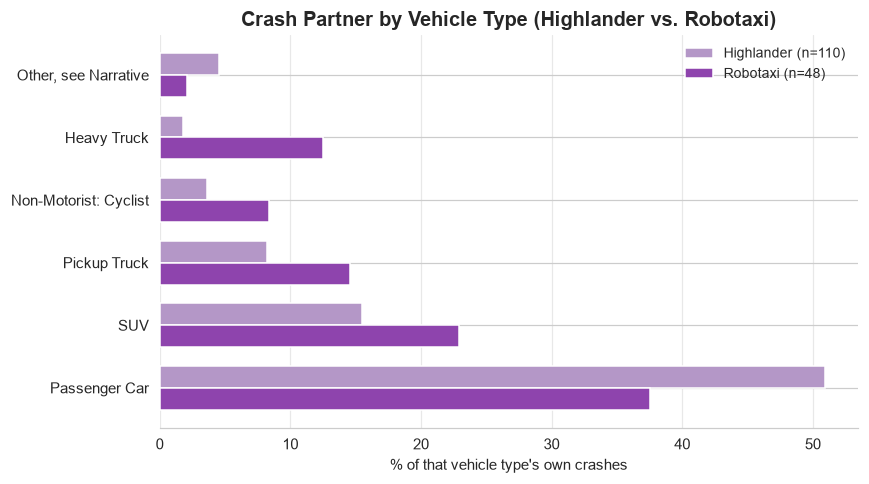

In [43]:
fig, ax = plt.subplots(figsize=(8, 4.5))
cw_all = zoox["Crash With"].value_counts()
top_partners = cw_all.head(6).index
highlander_mask = zoox["zoox_vehicle"] == HIGHLANDER_LABEL
robotaxi_mask = zoox["zoox_vehicle"] == ROBOTAXI_LABEL
n_highlander, n_robotaxi = int(highlander_mask.sum()), int(robotaxi_mask.sum())
highlander_cw = zoox.loc[highlander_mask, "Crash With"].value_counts(normalize=True).reindex(top_partners).fillna(0) * 100
robotaxi_cw = zoox.loc[robotaxi_mask, "Crash With"].value_counts(normalize=True).reindex(top_partners).fillna(0) * 100

y = np.arange(len(top_partners))
bar_h = 0.35
ax.barh(y + bar_h / 2, highlander_cw.values, height=bar_h, color="#B497C7", label=f"Highlander (n={n_highlander})")
ax.barh(y - bar_h / 2, robotaxi_cw.values, height=bar_h, color=ZOOX_COLOR, label=f"Robotaxi (n={n_robotaxi})")
ax.set_yticks(y)
ax.set_yticklabels(top_partners)
ax.set_xlabel("% of that vehicle type's own crashes")
ax.set_title("Crash Partner by Vehicle Type (Highlander vs. Robotaxi)", fontsize=13, fontweight="bold")
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)
plt.tight_layout()
plt.show()


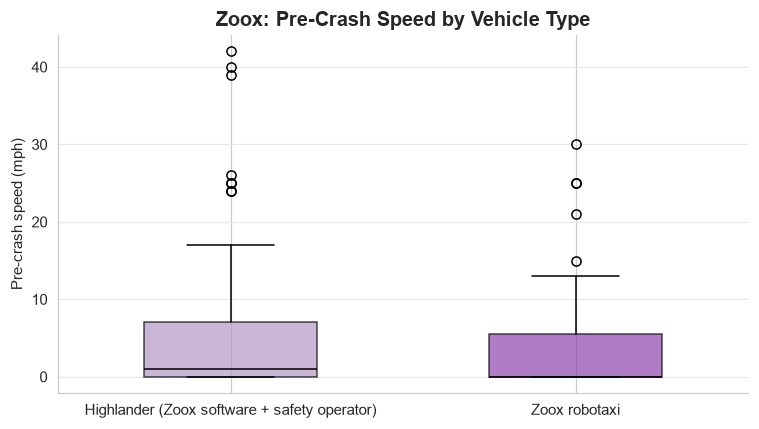

Highlander (Zoox software + safety operator): median=1 mph, n=110
Zoox robotaxi: median=0 mph, n=48


In [44]:
# Speed by vehicle type - compact box plot, one box per vehicle type
fig, ax = plt.subplots(figsize=(7, 4))
speed_by_vehicle = [pd.to_numeric(zoox.loc[zoox["zoox_vehicle"] == vt, speed_col], errors="coerce").dropna()
                    for vt in VEHICLE_COLORS]
bp = ax.boxplot(speed_by_vehicle, tick_labels=list(VEHICLE_COLORS.keys()), patch_artist=True, widths=0.5,
                 medianprops=dict(color="black"))
for patch, vt in zip(bp["boxes"], VEHICLE_COLORS):
    patch.set_facecolor(VEHICLE_COLORS[vt])
    patch.set_alpha(0.7)
ax.set_ylabel("Pre-crash speed (mph)")
ax.set_title("Zoox: Pre-Crash Speed by Vehicle Type", fontsize=13, fontweight="bold")
ax.grid(axis="y", color="#e8e8e8", linewidth=0.8, zorder=0)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

for vt in VEHICLE_COLORS:
    s = pd.to_numeric(zoox.loc[zoox["zoox_vehicle"] == vt, speed_col], errors="coerce").dropna()
    print(f"{vt}: median={s.median():.0f} mph, n={len(s)}")


### Injury rate: by vehicle type, and by schema era

                                     vehicle   n  k  proportion  ci_low  ci_high
Highlander (Zoox software + safety operator) 110 28       0.255   0.182    0.343
                               Zoox robotaxi  48  5       0.104  0.0453    0.222


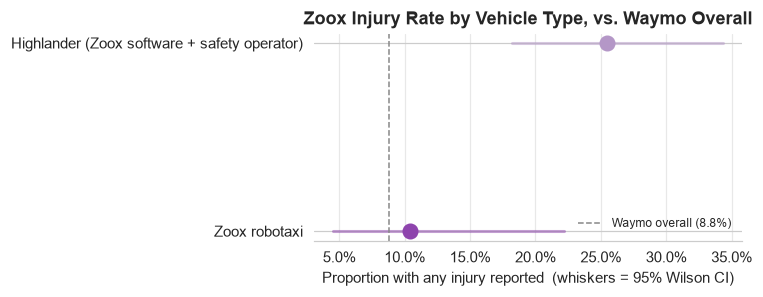

In [45]:
zoox["any_injury"] = ~zoox["injury_severity_bucket"].isin(["No Injury", "Unknown"])

waymo_overall = crashes[crashes["Reporting Entity"] == "Waymo LLC"]
waymo_overall_any_injury = ~waymo_overall["injury_severity_bucket"].isin(["No Injury", "Unknown"])
waymo_overall_k, waymo_overall_n = int(waymo_overall_any_injury.sum()), len(waymo_overall)

vehicle_injury_rows = []
for vt in VEHICLE_COLORS:
    sub = zoox[zoox["zoox_vehicle"] == vt]
    k, n = int(sub["any_injury"].sum()), len(sub)
    phat, lo, hi = wilson_ci(k, n)
    vehicle_injury_rows.append({"vehicle": vt, "n": n, "k": k, "proportion": phat, "ci_low": lo, "ci_high": hi})
vehicle_injury = pd.DataFrame(vehicle_injury_rows)
print(vehicle_injury.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 2.8))
y = np.arange(len(vehicle_injury))[::-1]
for yi, row in zip(y, vehicle_injury.itertuples()):
    color = VEHICLE_COLORS[row.vehicle]
    ax.plot([row.ci_low, row.ci_high], [yi, yi], color=color, linewidth=2, alpha=0.5, zorder=2)
    ax.scatter(row.proportion, yi, color=color, s=90, zorder=3)
waymo_overall_pct = waymo_overall_k / waymo_overall_n
ax.axvline(waymo_overall_pct, color="#888888", linestyle="--", linewidth=1,
           label=f"Waymo overall ({waymo_overall_pct*100:.1f}%)")
ax.set_yticks(y)
ax.set_yticklabels(vehicle_injury["vehicle"])
ax.set_xlabel("Proportion with any injury reported  (whiskers = 95% Wilson CI)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.set_title("Zoox Injury Rate by Vehicle Type, vs. Waymo Overall", fontsize=12, fontweight="bold")
ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)
plt.tight_layout()
plt.show()


In [46]:
# Injury rate by schema era (archive = pre-June 2025, current = 3rd Amendment)
source_injury_rows = []
for src in ["archive", "current"]:
    sub = zoox[zoox["data_source"] == src]
    k, n = int(sub["any_injury"].sum()), len(sub)
    phat, lo, hi = wilson_ci(k, n)
    source_injury_rows.append({"data_source": src, "n": n, "k": k, "proportion": phat, "ci_low": lo, "ci_high": hi})
source_injury = pd.DataFrame(source_injury_rows)
print(source_injury.to_string(index=False))

chi2, p_source, _, _ = stats.chi2_contingency(pd.crosstab(zoox["data_source"], zoox["any_injury"]))
print(f"\narchive vs. current injury rate: chi2={chi2:.2f}, p={p_source:.4f}")


data_source  n  k  proportion  ci_low  ci_high
    archive 94 24       0.255   0.178    0.352
    current 64  9       0.141  0.0758    0.246

archive vs. current injury rate: chi2=2.38, p=0.1231


**Note on the archive/current split:** `data_source` tracks which NHTSA schema a report was filed under (pre- vs. post-June 2025), not vehicle type - it's a reporting-era artifact, not a vehicle program. It's included here for completeness, but `zoox_vehicle` is the split that actually explains the pattern (see below).

### Zoox vs. Waymo injury rate, three ways

             group   n  k  proportion  ci_low  ci_high  p_fisher
          All Zoox 158 33       0.209   0.153    0.279  7.97e-06
   Highlander only 110 28       0.255   0.182    0.343  5.31e-07
Zoox robotaxi only  48  5       0.104  0.0453    0.222     0.609


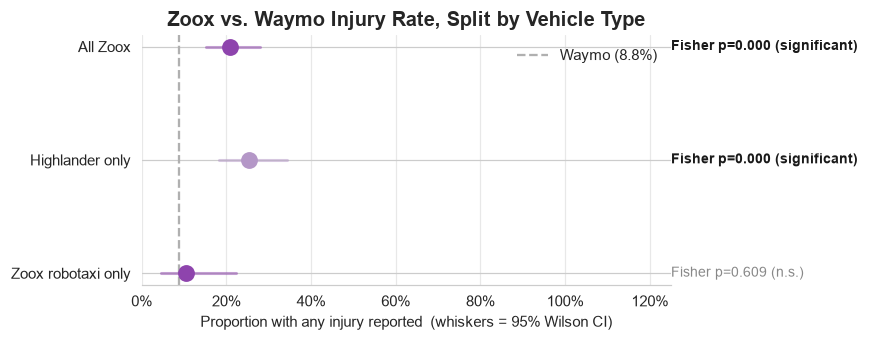

In [47]:
# All chi-square cells need expected counts >=5 to be reliable; the robotaxi
# group is small, so we use Fisher's exact test throughout for consistency
# across all three comparisons.
waymo_sub = crashes[crashes["Reporting Entity"] == "Waymo LLC"]
waymo_any_injury = ~waymo_sub["injury_severity_bucket"].isin(["No Injury", "Unknown"])
waymo_k, waymo_n = int(waymo_any_injury.sum()), len(waymo_sub)

three_way_rows = []
for label, sub in [
    ("All Zoox", zoox),
    ("Highlander only", zoox[zoox["zoox_vehicle"] == HIGHLANDER_LABEL]),
    ("Zoox robotaxi only", zoox[zoox["zoox_vehicle"] == ROBOTAXI_LABEL]),
]:
    k, n = int(sub["any_injury"].sum()), len(sub)
    phat, lo, hi = wilson_ci(k, n)
    table = [[k, n - k], [waymo_k, waymo_n - waymo_k]]
    odds, p_fisher = stats.fisher_exact(table)
    three_way_rows.append({"group": label, "n": n, "k": k, "proportion": phat, "ci_low": lo, "ci_high": hi, "p_fisher": p_fisher})

three_way = pd.DataFrame(three_way_rows)
print(three_way.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(three_way))[::-1]
colors = [ZOOX_COLOR, "#B497C7", ZOOX_COLOR]
for yi, row, color in zip(y, three_way.itertuples(), colors):
    ax.plot([row.ci_low, row.ci_high], [yi, yi], color=color, linewidth=2, alpha=0.5, zorder=2)
    ax.scatter(row.proportion, yi, color=color, s=100, zorder=3)
    tag = "significant" if row.p_fisher < 0.05 else "n.s."
    ax.text(1.0, yi, f"Fisher p={row.p_fisher:.3f} ({tag})", transform=ax.get_yaxis_transform(),
            va="center", ha="left", fontsize=9,
            color="#1a1a1a" if row.p_fisher < 0.05 else "#888888",
            fontweight="bold" if row.p_fisher < 0.05 else "normal")
ax.axvline(waymo_k / waymo_n, color=PEER_COLOR, linestyle="--", linewidth=1.5, label=f"Waymo ({waymo_k/waymo_n*100:.1f}%)", zorder=1)
ax.set_yticks(y)
ax.set_yticklabels(three_way["group"])
ax.set_xlabel("Proportion with any injury reported  (whiskers = 95% Wilson CI)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.set_title("Zoox vs. Waymo Injury Rate, Split by Vehicle Type", fontsize=13, fontweight="bold")
ax.set_xlim(0, 1.25)
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)
plt.tight_layout()
plt.show()


The elevated injury rate in "Zoox vs. Waymo" overall (20.9% vs. 8.8%) is almost entirely a **Highlander test-fleet** effect, not a robotaxi effect. The Highlander fleet's injury rate (25.5%, n=110) is significantly higher than Waymo's (Fisher's exact p<0.0001, still significant after Holm correction) - but the **Zoox robotaxi's** injury rate (10.4%, n=48) is statistically indistinguishable from Waymo's (Fisher's exact p=0.61), and the 95% CI is wide (4.5-22.2%), so a real difference either way can't be ruled out at this sample size. The injury-rate gap in the aggregate "Zoox" number is a finding about the safety-driver test fleet, not about the service the robotaxi itself is currently providing.


### Scenario: Struck From Behind While Stopped


In [48]:
# flag crashes where SV was stopped/parked and hit from the rear
crashes["rear_ended_while_stopped"] = (
    crashes["SV Pre-Crash Movement"].isin(["Stopped", "Parked"])
    & (crashes["SV Contact Area - Rear"] == "Y")
)

# only companies with >=30 crashes, otherwise the proportion is mostly noise
eligible_companies = company_counts[company_counts >= 30].index
rows = []
for company in eligible_companies:
    sub = crashes[crashes["Reporting Entity"] == company]
    n = len(sub)
    k = sub["rear_ended_while_stopped"].sum()
    phat, lo, hi = wilson_ci(k, n)
    rows.append({"company": company, "n": n, "k": k, "proportion": phat, "ci_low": lo, "ci_high": hi})

rear_ended_summary = pd.DataFrame(rows).sort_values("proportion", ascending=True)
rear_ended_summary


,company,n,k,proportion,ci_low,ci_high
3,Avride Inc.,82,2,0.0244,0.00671,0.0846
2,Cruise LLC,155,8,0.0516,0.0264,0.0985
4,May Mobility,46,7,0.152,0.0757,0.282
0,Waymo LLC,2309,392,0.17,0.155,0.186
1,"Zoox, Inc.",158,33,0.209,0.153,0.279


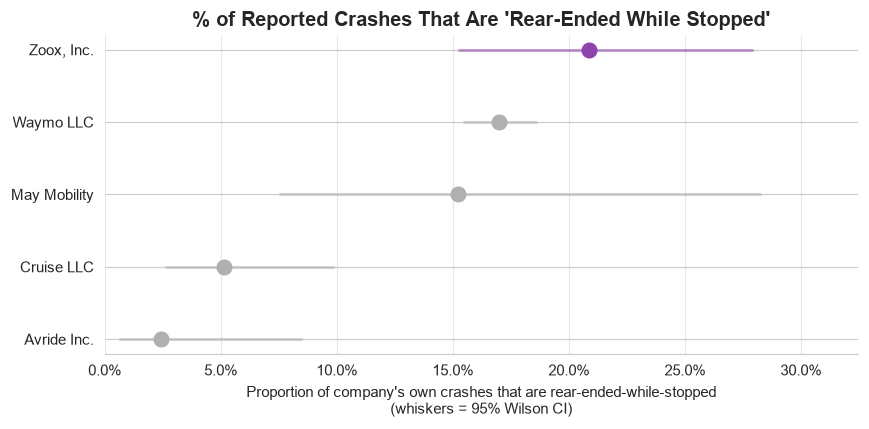

rear_ended_while_stopped  False  True 
Reporting Entity                      
Waymo LLC                  1917    392
Zoox, Inc.                  125     33

chi2 = 1.32, p-value = 0.2502


In [49]:
fig, ax = plt.subplots(figsize=(8, 0.5 * len(rear_ended_summary) + 1.5))
y = np.arange(len(rear_ended_summary))
colors = [ZOOX_COLOR if c == "Zoox, Inc." else PEER_COLOR for c in rear_ended_summary["company"]]
for yi, row, color in zip(y, rear_ended_summary.itertuples(), colors):
    ax.plot([row.ci_low, row.ci_high], [yi, yi], color=color, linewidth=2, alpha=0.5, zorder=2)
    ax.scatter(row.proportion, yi, color=color, s=90, zorder=3)
ax.set_yticks(y)
ax.set_yticklabels(rear_ended_summary["company"])
ax.set_xlabel("Proportion of company's own crashes that are rear-ended-while-stopped\n(whiskers = 95% Wilson CI)")
ax.set_title("% of Reported Crashes That Are 'Rear-Ended While Stopped'", fontsize=13, fontweight="bold")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.set_xlim(0, rear_ended_summary["ci_high"].max() * 1.15)
ax.grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)
plt.tight_layout()
plt.show()

# Zoox vs Waymo specifically
chi2, p, table = two_proportion_chisq(crashes, "Reporting Entity", "rear_ended_while_stopped",
                                        "Zoox, Inc.", "Waymo LLC")
print(table)
print(f"\nchi2 = {chi2:.2f}, p-value = {p:.4f}")


Zoox 20.9% [15.3–27.9%] vs. Waymo 17.0% [15.5–18.6%] — directionally higher but not significant (χ²=1.32, p=0.25). Can't distinguish from chance at Zoox's current sample size.

### Scenario: Low-Speed Crashes and Injury Rate


--- % at <=5 mph: Zoox, Inc. vs Waymo LLC ---
   company    n    k  proportion  ci_low  ci_high
Zoox, Inc.  158  113       0.715    0.64     0.78
 Waymo LLC 2309 1727       0.748    0.73    0.765
chi2 = 0.67, p-value = 0.4120

--- % with any injury reported: Zoox, Inc. vs Waymo LLC ---
   company    n   k  proportion  ci_low  ci_high
Zoox, Inc.  158  33       0.209   0.153    0.279
 Waymo LLC 2309 203      0.0879   0.077      0.1
chi2 = 23.63, p-value = 0.0000



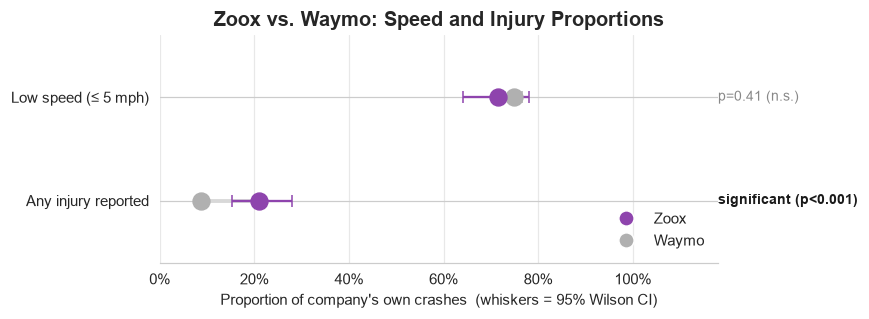

In [50]:
crashes["low_speed"] = pd.to_numeric(crashes[speed_col], errors="coerce") <= 5
crashes["any_injury"] = ~crashes["injury_severity_bucket"].isin(["No Injury", "Unknown"])

def compare_two(flag_col, label, group_a="Zoox, Inc.", group_b="Waymo LLC"):
    rows = []
    for company in [group_a, group_b]:
        sub = crashes[crashes["Reporting Entity"] == company]
        n = len(sub)
        k = sub[flag_col].sum()
        phat, lo, hi = wilson_ci(k, n)
        rows.append({"company": company, "n": n, "k": int(k), "proportion": phat, "ci_low": lo, "ci_high": hi})
    summary = pd.DataFrame(rows)
    chi2, p, table = two_proportion_chisq(crashes, "Reporting Entity", flag_col, group_a, group_b)
    print(f"--- {label}: {group_a} vs {group_b} ---")
    print(summary.to_string(index=False))
    print(f"chi2 = {chi2:.2f}, p-value = {p:.4f}\n")
    return summary, p

low_speed_summary, p_low_speed = compare_two("low_speed", "% at <=5 mph")
injury_summary, p_injury = compare_two("any_injury", "% with any injury reported")

# Dumbbell chart: one row per metric, Zoox vs Waymo dot connected by a line,
# whiskers = 95% Wilson CI - the headline visual for the significant/not-significant split.
fig, ax = plt.subplots(figsize=(8, 3))
metrics = [("Low speed (\u2264 5 mph)", low_speed_summary, p_low_speed),
           ("Any injury reported", injury_summary, p_injury)]
y_positions = list(range(len(metrics)))[::-1]

for yi, (label, summary, p) in zip(y_positions, metrics):
    zoox_row = summary[summary["company"] == "Zoox, Inc."].iloc[0]
    waymo_row = summary[summary["company"] == "Waymo LLC"].iloc[0]
    ax.plot([waymo_row["proportion"], zoox_row["proportion"]], [yi, yi], color="#d8d8d8", linewidth=2.5, zorder=1)
    for row, color in [(waymo_row, PEER_COLOR), (zoox_row, ZOOX_COLOR)]:
        ax.errorbar(row["proportion"], yi,
                    xerr=[[row["proportion"] - row["ci_low"]], [row["ci_high"] - row["proportion"]]],
                    fmt="o", color=color, markersize=11, capsize=4, elinewidth=1.5, zorder=3)
    tag = "significant (p<0.001)" if p < 0.001 else (f"p={p:.2f} (n.s.)" if p >= 0.05 else f"p={p:.3f}")
    ax.text(1.0, yi, tag, transform=ax.get_yaxis_transform(), va="center", ha="left", fontsize=9,
            color="#1a1a1a" if p < 0.05 else "#888888", fontweight="bold" if p < 0.05 else "normal")

ax.set_yticks(y_positions)
ax.set_yticklabels([m[0] for m in metrics])
ax.set_xlabel("Proportion of company's own crashes  (whiskers = 95% Wilson CI)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.set_title("Zoox vs. Waymo: Speed and Injury Proportions", fontsize=13, fontweight="bold")
ax.set_xlim(0, 1.18)
ax.set_ylim(-0.6, len(metrics) - 0.4)
ax.grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)

from matplotlib.lines import Line2D
legend_elems = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=ZOOX_COLOR, markersize=10, label="Zoox"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=PEER_COLOR, markersize=10, label="Waymo"),
]
ax.legend(handles=legend_elems, loc="lower right", frameon=False)
plt.tight_layout()
plt.show()


**Low speed (≤5 mph):** Zoox 71.5% vs. Waymo 74.8% — not significant (χ²=0.67, p=0.41).

**Any injury reported:** Zoox 20.9% vs. Waymo 8.8% — **significant** (χ²=23.63, p<0.0001). Not mileage-normalized, so not a safety claim — but a real difference in crash character worth investigating further (denser operating environment, reporting-threshold differences, or sample size are all plausible non-safety explanations).

### Scenario: Right-Turn Conflicts


Zoox:  20/158 = 12.7% [8.3-18.7%]
Waymo: 52/2309 = 2.3% [1.7-2.9%]
Fisher's exact test: p = 7.20e-09


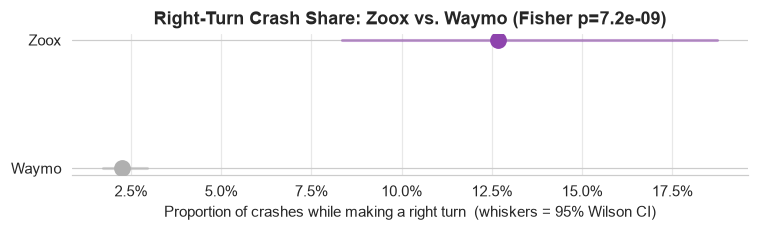

In [51]:
zoox_right_turn = zoox["SV Pre-Crash Movement"] == "Making Right Turn"
waymo_sub2 = crashes[crashes["Reporting Entity"] == "Waymo LLC"]
waymo_right_turn = waymo_sub2["SV Pre-Crash Movement"] == "Making Right Turn"

zk, zn = int(zoox_right_turn.sum()), len(zoox)
wk, wn = int(waymo_right_turn.sum()), len(waymo_sub2)
z_phat, z_lo, z_hi = wilson_ci(zk, zn)
w_phat, w_lo, w_hi = wilson_ci(wk, wn)
odds, p_rt = stats.fisher_exact([[zk, zn - zk], [wk, wn - wk]])

print(f"Zoox:  {zk}/{zn} = {z_phat*100:.1f}% [{z_lo*100:.1f}-{z_hi*100:.1f}%]")
print(f"Waymo: {wk}/{wn} = {w_phat*100:.1f}% [{w_lo*100:.1f}-{w_hi*100:.1f}%]")
print(f"Fisher's exact test: p = {p_rt:.2e}")

fig, ax = plt.subplots(figsize=(7, 2.2))
for yi, (label, phat, lo, hi, color) in enumerate([
    ("Zoox", z_phat, z_lo, z_hi, ZOOX_COLOR),
    ("Waymo", w_phat, w_lo, w_hi, PEER_COLOR),
][::-1]):
    ax.plot([lo, hi], [yi, yi], color=color, linewidth=2, alpha=0.5, zorder=2)
    ax.scatter(phat, yi, color=color, s=100, zorder=3)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Waymo", "Zoox"])
ax.set_xlabel("Proportion of crashes while making a right turn  (whiskers = 95% Wilson CI)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.set_title(f"Right-Turn Crash Share: Zoox vs. Waymo (Fisher p={p_rt:.1e})", fontsize=12, fontweight="bold")
ax.grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)
plt.tight_layout()
plt.show()


The share difference is real and large (Fisher's exact p < 0.0001) - this isn't noise. But "Zoox has more right-turn crashes than Waymo" and "Zoox has more right-turn crashes *involving vulnerable road users*" are different claims, and only the first one is supported. Breaking down what's actually in those 20 crashes:

zoox_vehicle
Highlander (Zoox software + safety operator)    15
Zoox robotaxi                                    5
Name: count, dtype: int64

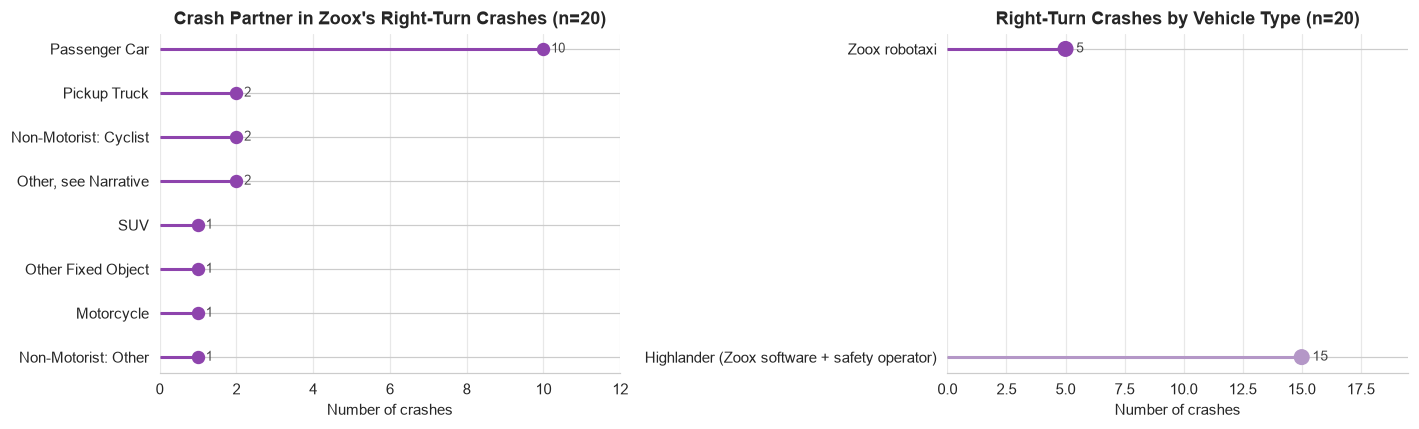

Crashes involving a non-motorist (cyclist/pedestrian/other): 3 of 20


In [52]:
zoox_rt_detail = zoox[zoox_right_turn].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

cw_rt = zoox_rt_detail["Crash With"].value_counts()
lollipop_on_ax(axes[0], cw_rt, "Crash Partner in Zoox's Right-Turn Crashes (n=20)", "Number of crashes", top_n=8)

veh_rt = zoox_rt_detail["zoox_vehicle"].value_counts()
y = np.arange(len(veh_rt))
colors = [VEHICLE_COLORS[v] for v in veh_rt.index]
axes[1].hlines(y, 0, veh_rt.values, color=colors, linewidth=2, zorder=2)
axes[1].scatter(veh_rt.values, y, color=colors, s=90, zorder=3)
for yi, v in zip(y, veh_rt.values):
    axes[1].text(v + veh_rt.values.max() * 0.03, yi, f"{v:,.0f}", va="center", fontsize=9, color="#444444")
axes[1].set_yticks(y)
axes[1].set_yticklabels(veh_rt.index)
axes[1].set_xlabel("Number of crashes")
axes[1].set_title("Right-Turn Crashes by Vehicle Type (n=20)", fontsize=12, fontweight="bold")
axes[1].set_xlim(0, veh_rt.values.max() * 1.3)
axes[1].grid(axis="x", color="#e8e8e8", linewidth=0.8, zorder=0)
for spine in ["top", "right", "left"]:
    axes[1].spines[spine].set_visible(False)
axes[1].tick_params(left=False)
print(veh_rt)

plt.tight_layout()
plt.show()

n_vru = zoox_rt_detail["Crash With"].str.contains("Non-Motorist", case=False, na=False).sum()
print(f"Crashes involving a non-motorist (cyclist/pedestrian/other): {n_vru} of {len(zoox_rt_detail)}")


Zoox's right-turn crash share (12.7%, n=20) is significantly higher than Waymo's (2.3%; Fisher's exact p<0.0001) - a real pattern, not a sample-size artifact, and it stays significant after correcting for all 13 tests run in this notebook. It is **mostly ordinary passenger-car conflicts during a right turn** (10 of 20 crash partners - and that narrower "Making Right Turn + Passenger Car" scenario is itself the single most over-represented scenario against Waymo, at a 9.7x ratio), not a vulnerable-road-user pattern, since only 3 of the 20 involve a cyclist or other non-motorist. It's concentrated in the Highlander fleet (15 of 20) but the robotaxi has 5 of the 20 - too few to say whether the pattern eases as the robotaxi's share of the fleet grows. We describe this as **an elevated rate of right-turn conflicts with ordinary traffic, concentrated in but not exclusive to the test fleet** - not a vulnerable-road-user safety issue, which the data doesn't support.


### Multiple-Comparisons Summary

Every Zoox-vs-Waymo test above - including the crash-scenario ranking - tests some version of the same underlying question ("does this Zoox slice differ from Waymo?"), so running many of them inflates the chance that at least one looks significant by chance alone. We collect every test into one table and correct with both **Bonferroni** (simple, conservative) and **Holm-Bonferroni** (step-down, less conservative but still controls the family-wise error rate) - and use Fisher's exact test throughout, even for the larger-sample comparisons, so every row in the table is directly comparable.


In [53]:
def holm_bonferroni(pvalues):
    """Holm's step-down correction. Returns adjusted p-values in the original order."""
    pvalues = np.asarray(pvalues, dtype=float)
    order = np.argsort(pvalues)
    m = len(pvalues)
    adjusted = np.empty(m)
    running_max = 0.0
    for rank, idx in enumerate(order):
        candidate = (m - rank) * pvalues[idx]
        running_max = max(running_max, candidate)
        adjusted[idx] = min(1.0, running_max)
    return adjusted

waymo_mc = crashes[crashes["Reporting Entity"] == "Waymo LLC"]
zoox_mc = crashes[crashes["Reporting Entity"] == "Zoox, Inc."].copy()
zoox_mc["zoox_vehicle"] = zoox_mc.apply(classify_zoox_vehicle, axis=1)
zoox_mc["crash_scenario"] = build_scenario(zoox_mc)
waymo_mc_sc = waymo_mc.copy()
waymo_mc_sc["crash_scenario"] = build_scenario(waymo_mc_sc)

def compare(flag_zoox, flag_waymo, label):
    kz, nz = int(flag_zoox.sum()), len(flag_zoox)
    kw, nw = int(flag_waymo.sum()), len(flag_waymo)
    _, p = stats.fisher_exact([[kz, nz - kz], [kw, nw - kw]])
    pz, loz, hiz = wilson_ci(kz, nz)
    pw, low, hiw = wilson_ci(kw, nw)
    return {
        "metric": label, "n_zoox": nz,
        "zoox_pct": pz * 100, "zoox_ci": f"[{loz*100:.1f}-{hiz*100:.1f}]",
        "waymo_pct": pw * 100, "waymo_ci": f"[{low*100:.1f}-{hiw*100:.1f}]",
        "test": "Fisher exact", "p_raw": p,
    }

mc_rows = [
    compare(zoox_mc["rear_ended_while_stopped"], waymo_mc["rear_ended_while_stopped"], "Rear-ended while stopped"),
    compare(zoox_mc["low_speed"], waymo_mc["low_speed"], "Low speed (<=5 mph)"),
    compare(zoox_mc["any_injury"], waymo_mc["any_injury"], "Any injury - all Zoox"),
    compare(zoox_mc.loc[zoox_mc["zoox_vehicle"] == HIGHLANDER_LABEL, "any_injury"], waymo_mc["any_injury"], "Any injury - Highlander only"),
    compare(zoox_mc.loc[zoox_mc["zoox_vehicle"] == ROBOTAXI_LABEL, "any_injury"], waymo_mc["any_injury"], "Any injury - robotaxi only"),
    compare(zoox_mc["SV Pre-Crash Movement"].eq("Making Right Turn"), waymo_mc["SV Pre-Crash Movement"].eq("Making Right Turn"), "Right-turn crash share"),
]

# add the crash-scenario-ranking tests from Section 5's scenario ranking, so every
# test run in this notebook is corrected together, not just the original six.
for scenario in eligible_scenarios:
    mc_rows.append(compare(
        zoox_mc["crash_scenario"] == scenario, waymo_mc_sc["crash_scenario"] == scenario,
        f"Scenario: {scenario}",
    ))

mc_table = pd.DataFrame(mc_rows)
mc_table["p_bonferroni"] = (mc_table["p_raw"] * len(mc_table)).clip(upper=1.0)
mc_table["p_holm"] = holm_bonferroni(mc_table["p_raw"].values)
mc_table["significant (Holm, a=0.05)"] = mc_table["p_holm"] < 0.05

pd.set_option("display.float_format", lambda x: f"{x:.4g}")
mc_table[["metric", "n_zoox", "zoox_pct", "zoox_ci", "waymo_pct", "waymo_ci", "test",
          "p_raw", "p_bonferroni", "p_holm", "significant (Holm, a=0.05)"]]


,metric,n_zoox,zoox_pct,zoox_ci,waymo_pct,waymo_ci,test,p_raw,p_bonferroni,p_holm,"significant (Holm, a=0.05)"
0,Rear-ended while stopped,158,20.89,[15.3-27.9],16.98,[15.5-18.6],Fisher exact,0.2302,1,0.8574,False
1,Low speed (<=5 mph),158,71.52,[64.0-78.0],74.79,[73.0-76.5],Fisher exact,0.3951,1,0.8574,False
2,Any injury - all Zoox,158,20.89,[15.3-27.9],8.792,[7.7-10.0],Fisher exact,7.971e-06,0.0001036,7.971e-05,True
3,Any injury - Highlander only,110,25.45,[18.2-34.3],8.792,[7.7-10.0],Fisher exact,5.307e-07,6.899e-06,6.368e-06,True
4,Any injury - robotaxi only,48,10.42,[4.5-22.2],8.792,[7.7-10.0],Fisher exact,0.6089,1,0.8574,False
5,Right-turn crash share,158,12.66,[8.3-18.7],2.252,[1.7-2.9],Fisher exact,7.202e-09,9.363e-08,9.363e-08,True
6,Scenario: Proceeding Straight + Passenger Car,158,14.56,[9.9-20.9],9.744,[8.6-11.0],Fisher exact,0.05588,0.7264,0.3353,False
7,"Scenario: Stopped/parked, rear-ended by Passenger Car",158,13.29,[8.9-19.5],6.107,[5.2-7.2],Fisher exact,0.001317,0.01713,0.01186,True
8,Scenario: Proceeding Straight + SUV,158,11.39,[7.3-17.3],6.366,[5.4-7.4],Fisher exact,0.02039,0.2651,0.1631,False
9,Scenario: Making Right Turn + Passenger Car,158,6.329,[3.5-11.3],0.6496,[0.4-1.1],Fisher exact,1.243e-06,1.616e-05,1.367e-05,True


**Across all 13 tests - the original 6 plus the 7 crash-scenario comparisons - 5 stay significant after Holm correction:** all-Zoox injury rate, Highlander-only injury rate, right-turn crash share, the "Making Right Turn + Passenger Car" scenario specifically, and the "Stopped/parked, rear-ended by Passenger Car" scenario specifically. Everything else - rear-ended-while-stopped in aggregate, low speed, robotaxi-only injury rate, and four of the other five scenario comparisons - does not survive correction. Two results are worth flagging as judgment calls rather than clean negatives: "Proceeding Straight + SUV" is nominally significant before correction (p=0.02) but not after, and the plain "Stopped + Passenger Car" scenario is *under*-represented for Zoox (not over), which correction also washes out. Running the scenario-level tests alongside the original six doesn't change any of the original three conclusions - it adds two new, more specific findings about exactly which scenarios drive them.


## 6. Multivariate: Pivot Tables & Heatmaps


### Company x crash partner


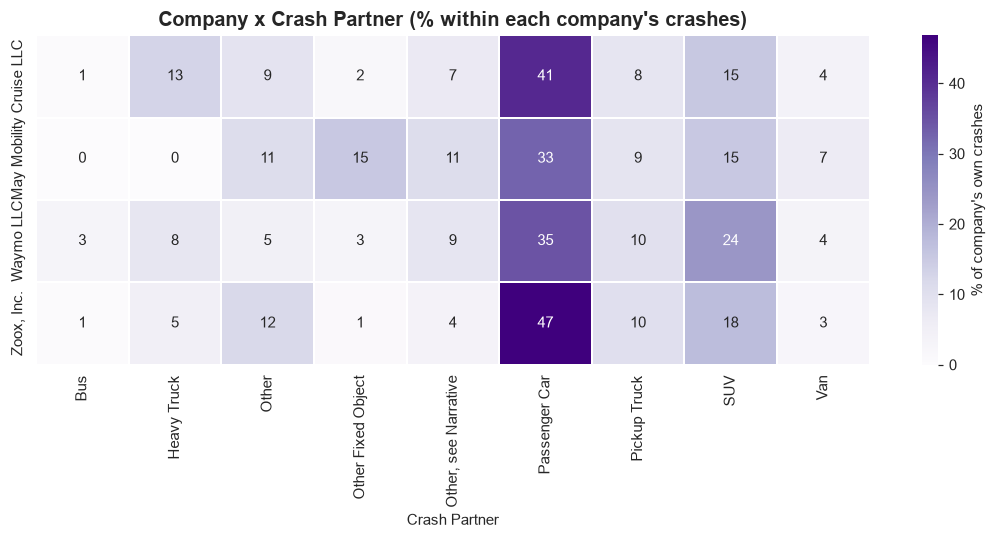

In [54]:
# only companies with a decent sample, else the heatmap is mostly noise.
# GM and Transdev are excluded here (not just "small") - after the Same-Incident-ID
# dedup they're down to ~1 row each, since most of their crashes were duplicate
# co-filings of Cruise's and Waymo's crashes respectively (see Section 2).
focus_companies = ["Zoox, Inc.", "Waymo LLC", "Cruise LLC", "May Mobility"]
focus = crashes[crashes["Reporting Entity"].isin(focus_companies)]

# row-normalize so we're comparing proportions, not raw counts
top_crash_with = crash_with_counts.head(8).index
pivot_cw = pd.crosstab(focus["Reporting Entity"], focus["Crash With"].where(focus["Crash With"].isin(top_crash_with), "Other"))
pivot_cw_pct = pivot_cw.div(pivot_cw.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(pivot_cw_pct, annot=True, fmt=".0f", cmap="Purples", linewidths=1, linecolor="white",
            cbar_kws={"label": "% of company's own crashes"}, ax=ax)
ax.set_title("Company x Crash Partner (% within each company's crashes)", fontsize=13, fontweight="bold")
ax.set_xlabel("Crash Partner")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


Zoox skews most toward passenger cars (46.8%, highest of the group) and has one of the lowest heavy-truck shares (5.1%, vs. Cruise's 12.9% and Waymo's 8.1%) — May Mobility's 0% is its low-speed shuttle routes, not a comparable fleet mix, so it's not really a competing data point here.

### Company x pre-crash movement


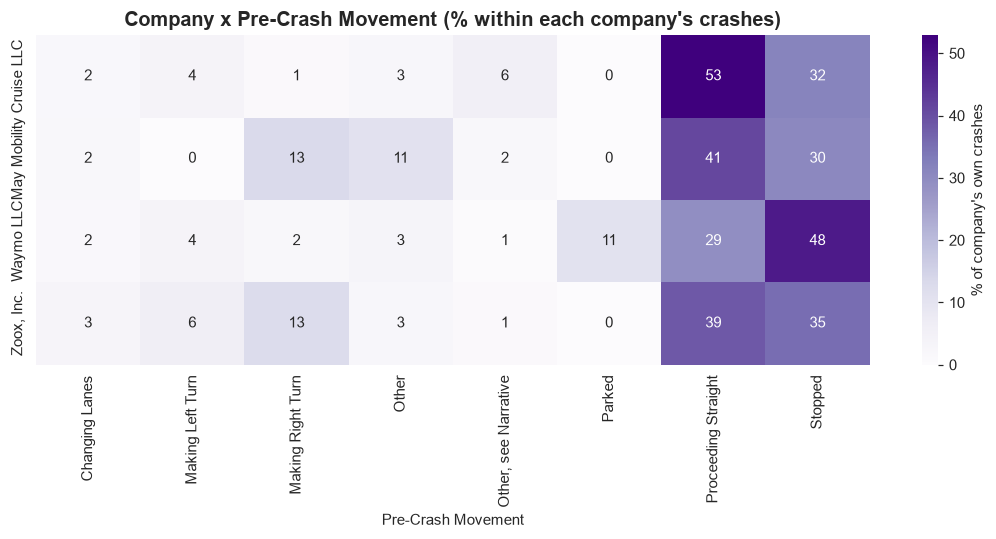

In [55]:
top_movements = movement_counts.head(7).index
pivot_mv = pd.crosstab(focus["Reporting Entity"], focus["SV Pre-Crash Movement"].where(focus["SV Pre-Crash Movement"].isin(top_movements), "Other"))
pivot_mv_pct = pivot_mv.div(pivot_mv.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(pivot_mv_pct, annot=True, fmt=".0f", cmap="Purples", cbar_kws={"label": "% of company's own crashes"}, ax=ax)
ax.set_title("Company x Pre-Crash Movement (% within each company's crashes)", fontsize=13, fontweight="bold")
ax.set_xlabel("Pre-Crash Movement")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


Zoox's "Stopped" share (35.4%) is lower than Waymo's (48.4%), but its "Making Right Turn" share (12.7%) is far higher than Cruise's (1.3%) or Waymo's (2.3%) — comparable only to May Mobility's low-speed shuttle routes (13.0%). The Zoox/Waymo gap is a significant difference (see the right-turn test and crash-partner breakdown in Section 5), driven mostly by ordinary passenger-car conflicts and concentrated in the Highlander test fleet, not a vulnerable-road-user pattern.

### Speed x severity


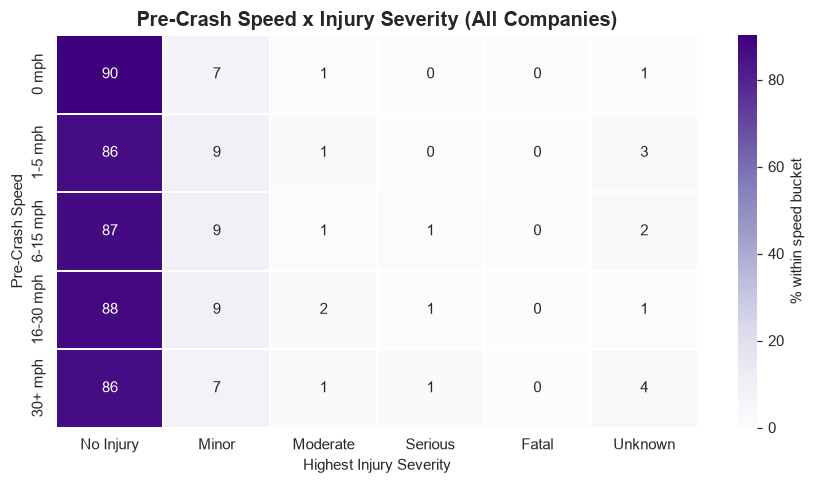

In [56]:
# bucket speed into readable ranges for the heatmap axis
speed_numeric = pd.to_numeric(crashes[speed_col], errors="coerce")
speed_bucket = pd.cut(speed_numeric, bins=[-0.1, 0, 5, 15, 30, 200],
                       labels=["0 mph", "1-5 mph", "6-15 mph", "16-30 mph", "30+ mph"])

pivot_speed_sev = pd.crosstab(speed_bucket, crashes["injury_severity_bucket"])
pivot_speed_sev_pct = pivot_speed_sev.div(pivot_speed_sev.sum(axis=1), axis=0) * 100
pivot_speed_sev_pct = pivot_speed_sev_pct[[c for c in severity_order if c in pivot_speed_sev_pct.columns]]

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pivot_speed_sev_pct, annot=True, fmt=".0f", cmap="Purples", linewidths=1, linecolor="white",
            cbar_kws={"label": "% within speed bucket"}, ax=ax)
ax.set_title("Pre-Crash Speed x Injury Severity (All Companies)", fontsize=13, fontweight="bold")
ax.set_xlabel("Highest Injury Severity")
ax.set_ylabel("Pre-Crash Speed")
plt.tight_layout()
plt.show()


Injury rate is close to flat across speed buckets (roughly 8–12% minor-or-worse at every bucket, including 0 mph) — crash orientation (e.g. struck from behind) likely matters more for injury outcome than raw speed.

## 7. SQL Validation

The same proportions as a DuckDB query against the in-memory dataframe, no separate database needed - a sanity check that the pandas results above are correct, not a new analysis.


In [57]:
import duckdb

sql_result = duckdb.sql("""
    SELECT
        "Reporting Entity" AS company,
        COUNT(*) AS total_crashes,
        ROUND(100.0 * SUM(CASE WHEN rear_ended_while_stopped THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_rear_ended_while_stopped,
        ROUND(100.0 * SUM(CASE WHEN any_injury THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_any_injury
    FROM crashes
    GROUP BY "Reporting Entity"
    HAVING COUNT(*) >= 30
    ORDER BY total_crashes DESC
""").df()

sql_result


,company,total_crashes,pct_rear_ended_while_stopped,pct_any_injury
0,Waymo LLC,2309,17,8.8
1,"Zoox, Inc.",158,20.9,20.9
2,Cruise LLC,155,5.2,16.8
3,Avride Inc.,82,2.4,3.7
4,May Mobility,46,15.2,6.5


## 8. Key Findings

**Answering the three opening questions:** (1) scenario ranking surfaces two specific, statistically significant over-represented scenarios, not a vague "Zoox crashes differently"; (2) one of those two carries over to the robotaxi and one doesn't have enough robotaxi data yet to tell, and the much-discussed aggregate injury-rate gap turns out not to be a robotaxi finding at all; (3) city differences exist, but the sample is still small.

- Waymo accounts for 78.1% of reported crashes (2,309 of 2,956) after deduplication - raw counts track exposure (fleet size, years operating), not safety.
- Of 3,773 raw report rows, 817 (21.7%) were duplicates: 437 same-company re-filings (Report ID + latest Report Version), plus 380 **cross-company** duplicates where two entities (an operator and a manufacturer co-filer, e.g. Cruise + General Motors, Waymo + Transdev) reported the same physical crash under a shared `Same Incident ID`. Zoox had zero cross-company duplicates - its 158-crash count is unchanged by this fix.
- **"Zoox" is two vehicle programs, not one.** Of its 158 crashes, 110 are the **Highlander test fleet (Zoox self-driving software, safety operator onboard)** and 48 are the **Zoox robotaxi (driverless, no operator)** - confirmed independently by `Driver / Operator Type` (all 110 Highlander rows show an in-vehicle operator; 46 of 48 robotaxi rows show none recorded) and by narrative text ("disengaged" and "manual mode" appear only in Highlander narratives). The robotaxi has outnumbered the Highlander fleet in monthly crash volume since May 2024, but the test fleet is still active alongside it, not retired.
- **Scenario ranking surfaces two specific, statistically significant patterns:** right turns into a passenger car (6.3% of Zoox's crashes vs. 0.65% of Waymo's - a 9.7x ratio, Fisher's exact p<0.0001) and being rear-ended by a passenger car while stopped (13.3% vs. 6.1% - a 2.2x ratio, p=0.0013). Both stay significant after Holm-correcting across all 13 tests run in this notebook.
- **The rear-end-by-passenger-car scenario carries over to the robotaxi (10.4% vs. Waymo's 6.1%); the right-turn scenario doesn't have enough robotaxi data yet to tell** (only 1 robotaxi crash in that exact scenario). More broadly, the robotaxi's overall injury rate (10.4%, n=48) is statistically indistinguishable from Waymo's (p=0.61) - the much-discussed "Zoox has a higher injury rate than Waymo" result (20.9% vs. 8.8% in aggregate) is a **Highlander test-fleet effect** (25.5%, still significant after correction), not something the robotaxi itself currently shows.
- Zoox's right-turn crash share (12.7%, n=20) is significantly higher than Waymo's (2.3%; p<0.0001, still significant after correction) but is mostly ordinary passenger-car conflicts (10 of 20), not a vulnerable-road-user pattern (only 3 of 20 involve a cyclist or other non-motorist); 15 of 20 are Highlander, 5 of 20 are robotaxi.
- Zoox's rear-ended-while-stopped rate (20.9%) and low-speed rate (71.5%), taken in aggregate across all crash partners, are both statistically indistinguishable from Waymo's and stay non-significant after correction - it's only once "rear-ended" is narrowed to passenger-car partners specifically that a significant difference appears, which is why the scenario-level ranking is more actionable than either aggregate flag alone.
- **City differences exist but the sample is small:** Las Vegas shows a right-turn crash share of 17.7% vs. San Francisco's 9.5%, in samples of 62 and 84 crashes respectively - descriptive, not tested, but relevant to predicting what a new city's crash mix might look like before it has crash history of its own.
- Running all 13 Zoox-vs-Waymo tests in this notebook (6 original + 7 scenario-level) and correcting with Holm-Bonferroni leaves 5 significant: all-Zoox injury rate, Highlander-only injury rate, right-turn crash share, and the two scenario-specific tests above - see Section 5's multiple-comparisons table.
- `Lighting`, `Posted Speed Limit`, and `Mileage` exist only in the pre-3rd-Amendment schema (2021-2025); exact crash coordinates are redacted as PII for every company, so the geospatial view here is city-level, not block-level.


## 9. Recommendations

**What a Zoox validation team could prioritize**, each tied to a specific number above - phrased as priorities to investigate further, not as proof of a safety problem:

1. **Prioritize right-turn-into-passenger-car scenarios in simulation and on-road validation**, especially at busy intersections. This is the single most over-represented scenario against Waymo (9.7x ratio, 6.3% vs. 0.65% of own crashes, p<0.0001, still significant after correcting for all 13 tests) and it's ordinary traffic, not an edge case - 10 of Zoox's 20 right-turn crashes involve a passenger car.
2. **Validate stopped-vehicle, rear-ended-by-passenger-car scenarios specifically**, rather than "rear-ended while stopped" generically. Narrowing to passenger-car partners is what makes the pattern statistically significant (13.3% vs. 6.1%, p=0.0013) even though the broader flag (20.9% vs. 17.0%) isn't - and unlike the right-turn scenario, this one already shows up in the robotaxi (10.4% vs. Waymo's 6.1%), so it isn't purely a test-fleet artifact.
3. **Don't generalize the Highlander test fleet's injury numbers to the robotaxi.** The Highlander fleet's injury rate (25.5%) is significantly higher than Waymo's and survives correction; the robotaxi's (10.4%, n=48) does not differ significantly from Waymo's. Treating the aggregate "Zoox" injury number as a robotaxi risk signal would misdirect validation effort toward a vehicle program that isn't carrying the actual service riders use.
4. **Treat road-network design, not just the vehicle, as a factor in predicting a new city's crash mix.** Las Vegas's right-turn share (17.7%) is nearly double San Francisco's (9.5%) in this still-small sample (n=62 and 84) - worth revisiting with more data before a launch in a city with road geometry unlike either.
5. **Grow the robotaxi-only sample before treating any robotaxi-specific proportion as settled.** Every robotaxi-only estimate here (injury rate, right-turn carryover, most scenario-carryover checks) is limited by small n (48 overall, and as few as 0-7 once split by scenario) and wide confidence intervals; several scenarios in Section 5 are explicitly flagged "too few robotaxi crashes to tell" for this reason, and that will resolve naturally as the robotaxi's share of the fleet keeps growing past its May 2024 crossover point.


## 10. Limitations

- **Not normalized by miles driven.** Nothing here ranks companies by safety - we have no exposure data.
- **Most Zoox crashes come from the Highlander test fleet, not the robotaxi** (110 of 158, vs. 48 robotaxi), so any unsplit "Zoox" comparison mixes two very different vehicle programs (supervised test-fleet driving vs. autonomous rider-only service). We split by vehicle type wherever it changes the conclusion, but any Zoox number elsewhere in this notebook that isn't split this way is a blend of both.
- **The `crash_scenario` field is one reasonable construction, not the only one.** It combines pre-crash movement and crash partner, with a special case for struck-from-behind-while-stopped - a different combination scheme (e.g. adding speed or location) could rank scenarios differently.
- **The robotaxi carryover labels depend on a chosen threshold** (robotaxi share >=1.5x Waymo's share to call it "persists," minimum 5 robotaxi crashes to say anything at all). These are reasonable, stated cutoffs, not the only valid ones - a stricter or looser bar could relabel the borderline cases.
- **Narrative keyword tagging is literal keyword matching, not NLP or full text analysis.** It undercounts anything phrased differently than the literal pattern and can't distinguish context; matches are not manually verified.
- **The San Francisco vs. Las Vegas comparison is descriptive, not a statistical test** - 62 and 84 crashes respectively is enough to describe a pattern but too few to confirm one.
- **Self-reported, unverified.** Companies file these reports themselves; there is no independent verification layer.
- **Schema changed mid-dataset** (June 2025, 3rd Amendment) - some fields (`Lighting`, `Posted Speed Limit`, `Mileage`) exist only in the older schema and are noted as such wherever used.
- **Cross-company duplicate resolution is a best-effort heuristic** (keep the row whose `Reporting Entity` matches its `Operating Entity`, with a fuzzy fallback for inconsistently formatted names) - not manually verified row by row.
- **Redacted fields are informative, not missing** - e.g., `Within ODD?` and `Narrative` are redacted for confidential business information and kept as an explicit "Redacted" category.
- **No ground-truth fault field** - any "who struck whom" framing in this notebook is an inference from contact-area and movement fields, not a stated fact in the data.
- **Exact crash coordinates are redacted** as potential PII for every company - the geospatial section approximates using public city-centroid coordinates, not true crash-level geocoordinates.
- **Small samples for further slicing.** The robotaxi-only group (n=48) and the right-turn detail breakdown (n=20) are both small enough that individual-category counts should be read as illustrative, not precise rates.

This dataset can tell you *how* ADS crashes happen - crash type, movement, speed, severity - but on its own it cannot tell you *which company is safer*, and for Zoox specifically, it cannot tell you much about the robotaxi in isolation unless the vehicle-type split is applied.
